In [1]:
import json
import os
import re
import time
import unicodedata
from datetime import datetime, timezone
from pathlib import Path

import ftfy
import pandas as pd
import requests
from lingua import Language, LanguageDetectorBuilder
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

BASE_URL = "https://openlibrary.org"
HEADERS = {"User-Agent": "AdvancedDataMining/1.0 (your-email@example.com)"}
# `language:eng` makes Open Library return the matching English edition of each work
SEARCH_QUERY = "subject:fiction language:eng"
SEARCH_FIELDS = "key,title,author_name,description,subject,editions,editions.key,editions.title,editions.language"
N_BOOKS = 50_000  # target number of English books (after filtering)
BATCH_SIZE = 50
REQUEST_DELAY = 1.0

RAW_DIR = Path("data/raw/batches_eng")
PROGRESS_PATH = RAW_DIR / "_progress.json"
PROCESSED_DIR = Path("data/processed")
JSON_PATH = PROCESSED_DIR / "books.json"
PARQUET_PATH = PROCESSED_DIR / "books.parquet"

session = requests.Session()
session.headers.update(HEADERS)
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=["GET"])
session.mount("https://", HTTPAdapter(max_retries=retry))

In [2]:
# English-only filter:
# 1. Open Library must return an edition catalogued as English only (language == ["eng"]);
#    its title is used as the book name, e.g. "O Alquimista" -> "The Alchemist".
# 2. The (work-level) description must be detected as English.
ENGLISH_CODE = "eng"

# Languages that steal short/mixed English texts, excluded from description detection
NOISY_LANGUAGES = [
    Language.LATIN, Language.ESPERANTO, Language.SOMALI, Language.SWAHILI, Language.TSWANA,
    Language.SOTHO, Language.XHOSA, Language.ZULU, Language.TSONGA, Language.YORUBA,
    Language.SHONA, Language.GANDA, Language.MAORI, Language.TAGALOG, Language.WELSH,
    Language.IRISH, Language.AFRIKAANS, Language.BASQUE, Language.ALBANIAN, Language.NYNORSK,
    Language.CATALAN,
]
description_detector = LanguageDetectorBuilder.from_all_languages_without(*NOISY_LANGUAGES).build()


def get_description(doc):
    description = doc.get("description")
    if isinstance(description, dict):
        description = description.get("value")
    return (description or "").strip()


def get_english_edition(doc):
    """The edition Open Library matched for `language:eng`, if it is English-only."""
    editions = (doc.get("editions") or {}).get("docs", [])
    if editions and editions[0].get("language") == [ENGLISH_CODE] and editions[0].get("title"):
        return editions[0]
    return None


def is_latin_script(text):
    return all(not ch.isalpha() or "LATIN" in unicodedata.name(ch, "") for ch in text)


def is_english_description(description):
    return bool(description) and description_detector.detect_language_of(description[:2000]) == Language.ENGLISH


def is_english_book(doc):
    edition = get_english_edition(doc)
    return (
        edition is not None
        and is_latin_script(edition["title"])
        and is_english_description(get_description(doc))
    )


# Sanity check
english_edition = {"docs": [{"title": "Dune", "language": ["eng"]}]}
bilingual_edition = {"docs": [{"title": "El Principito / The Little Prince", "language": ["spa", "eng"]}]}
for label, doc in [
    ("English", {"editions": english_edition, "description": "Set on the desert planet Arrakis, Dune is the story of Paul Atreides."}),
    ("bilingual edition", {"editions": bilingual_edition, "description": "A pilot stranded in the desert meets a young prince."}),
    ("French description", {"editions": english_edition, "description": "Le Petit Prince est une œuvre de langue française."}),
]:
    print(f"{label:20} -> {is_english_book(doc)}")

English              -> True
bilingual edition    -> False
French description   -> False


In [3]:
def batch_path(batch_no):
    return RAW_DIR / f"batch_{batch_no:05d}.jsonl"


def atomic_write(path, text):
    """Write via a temp file + rename, so a crash never leaves a half-written file."""
    tmp_path = path.with_name(path.name + ".tmp")
    with tmp_path.open("w", encoding="utf-8") as f:
        f.write(text)
        f.flush()
        os.fsync(f.fileno())
    tmp_path.replace(path)


def batch_docs(path):
    docs = []
    with path.open(encoding="utf-8") as f:
        for line in f:
            docs.extend(json.loads(json.loads(line)["response"]).get("docs", []))
    return docs


def load_progress():
    """batch_no -> list of English work keys found in that batch."""
    if PROGRESS_PATH.exists():
        return {int(k): v for k, v in json.loads(PROGRESS_PATH.read_text(encoding="utf-8")).items()}
    return {}


def save_progress(progress):
    atomic_write(PROGRESS_PATH, json.dumps({str(k): v for k, v in sorted(progress.items())}))


def fetch_batch(batch_no):
    """Download one search page and land the raw, unedited response as JSONL."""
    offset = batch_no * BATCH_SIZE
    response = session.get(
        f"{BASE_URL}/search.json",
        params={
            "q": SEARCH_QUERY,
            "fields": SEARCH_FIELDS,
            "sort": "readinglog",
            "limit": BATCH_SIZE,
            "offset": offset,
        },
        timeout=(10, 120),
    )
    response.raise_for_status()
    record = {
        "batch_no": batch_no,
        "offset": offset,
        "url": response.url,
        "status_code": response.status_code,
        "fetched_at": datetime.now(timezone.utc).isoformat(),
        "response": response.text,
    }
    atomic_write(batch_path(batch_no), json.dumps(record, ensure_ascii=False) + "\n")
    return json.loads(response.text).get("docs", [])


def download_all():
    """Fetch batches until N_BOOKS unique English books are landed.

    Safe to stop at any time: finished batches are kept on disk and skipped on the next run.
    """
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    for tmp in RAW_DIR.glob("*.tmp"):
        tmp.unlink()

    progress = load_progress()
    english_keys = set()
    batch_no = 0
    started = time.time()
    while len(english_keys) < N_BOOKS:
        path = batch_path(batch_no)
        if batch_no in progress and path.exists():
            english_keys.update(progress[batch_no])
            batch_no += 1
            continue

        if path.exists():
            docs = batch_docs(path)  # landed, but progress not saved before the stop
        else:
            docs = fetch_batch(batch_no)
            time.sleep(REQUEST_DELAY)
        if not docs:
            print("No more search results.")
            break

        progress[batch_no] = [doc["key"] for doc in docs if is_english_book(doc)]
        save_progress(progress)
        english_keys.update(progress[batch_no])
        print(
            f"batch {batch_no:05d} | +{len(progress[batch_no]):>2}/{len(docs)} English"
            f" | {len(english_keys):>6}/{N_BOOKS} | {time.time() - started:6.0f}s",
            flush=True,
        )
        batch_no += 1
    print(f"Done: {len(english_keys)} English books from {batch_no} batches in {RAW_DIR}")

In [4]:
#download_all()

In [10]:
import json
from pathlib import Path

import pandas as pd

# Paths setup
RAW_DIR = Path("data/raw/batches_eng")
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

JSON_PATH = PROCESSED_DIR / "books.json"
PARQUET_PATH = PROCESSED_DIR / "books.parquet"

TARGET = 50_000
books_by_key = {}

batch_files = sorted(RAW_DIR.glob("batch_*.jsonl"))

# Iterating through batch files to extract unique English works
for path in batch_files:
    with path.open("r", encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            record = json.loads(line)
            response = json.loads(record["response"])
            docs = response.get("docs", [])

            for doc in docs:
                key = doc.get("key")

                if not key or key in books_by_key:
                    continue

                if not is_english_book(doc):
                    continue

                edition = get_english_edition(doc)
                description = get_description(doc)

                books_by_key[key] = {
                    "work_key": key,
                    "title": edition["title"],
                    "author_name": doc.get("author_name", []),
                    "description": description,
                    "genres": doc.get("subject", []),
                    "edition_key": edition.get("key"),
                }

    print(f"{path.name}: {len(books_by_key):,} unique books found.")

    if len(books_by_key) >= TARGET:
        break

books = list(books_by_key.values())[:TARGET]

print(f"\nNumber of books to save: {len(books):,}")

if len(books) < TARGET:
    print(f"WARNING: Found only {len(books):,} books instead of {TARGET:,}.")

df = pd.DataFrame(books)

df.to_json(
    JSON_PATH,
    orient="records",
    force_ascii=False,
    indent=2,
)

df.to_parquet(
    PARQUET_PATH,
    engine="pyarrow",
    index=False,
)

print("\nData export complete.")
print(f"JSON: {JSON_PATH} ({len(df):,} records)")
print(f"Parquet: {PARQUET_PATH} ({len(df):,} records)")

batch_00000.jsonl: 47 unique books found.
batch_00001.jsonl: 95 unique books found.
batch_00002.jsonl: 141 unique books found.
batch_00003.jsonl: 190 unique books found.
batch_00004.jsonl: 236 unique books found.
batch_00005.jsonl: 283 unique books found.
batch_00006.jsonl: 330 unique books found.
batch_00007.jsonl: 376 unique books found.
batch_00008.jsonl: 421 unique books found.
batch_00009.jsonl: 468 unique books found.
batch_00010.jsonl: 514 unique books found.
batch_00011.jsonl: 561 unique books found.
batch_00012.jsonl: 605 unique books found.
batch_00013.jsonl: 653 unique books found.
batch_00014.jsonl: 701 unique books found.
batch_00015.jsonl: 749 unique books found.
batch_00016.jsonl: 796 unique books found.
batch_00017.jsonl: 844 unique books found.
batch_00018.jsonl: 892 unique books found.
batch_00019.jsonl: 940 unique books found.
batch_00020.jsonl: 986 unique books found.
batch_00021.jsonl: 1,031 unique books found.
batch_00022.jsonl: 1,075 unique books found.
batch_000

Total books: 50,000
Books with at least one selected genre: 43,871
Books with no matching selected genre (unlisted): 6,129

Books per genre:
Crime/Mystery: 6,574
Romance: 17,405
Fantasy: 5,909
Contemporary: 4,474
Science Fiction: 4,262
Action/Adventure: 3,942
Horror: 2,255
Literary: 1,206
Comedy: 2,083
Children Books: 18,082
Historical: 7,481
Thriller: 3,032
unlisted: 6,129

Before matching, tags are lowercased, Unicode-repaired, stripped of punctuation and invisible characters, and whitespace-normalized.
Empty tags and duplicates created by cleaning are removed.
Matching uses normalized category words within existing tags and the explicit mappings below.
Crime or mystery -> Crime/Mystery; action or adventure -> Action/Adventure.
Non-fiction, non fiction, and nonfiction -> Non-fiction.
Children, children's, or juvenile -> Children Books; comedy or humorous -> Comedy.
Catalog metadata tags are ignored when matching selected genres.
Matched books keep only selected genres; all other tags

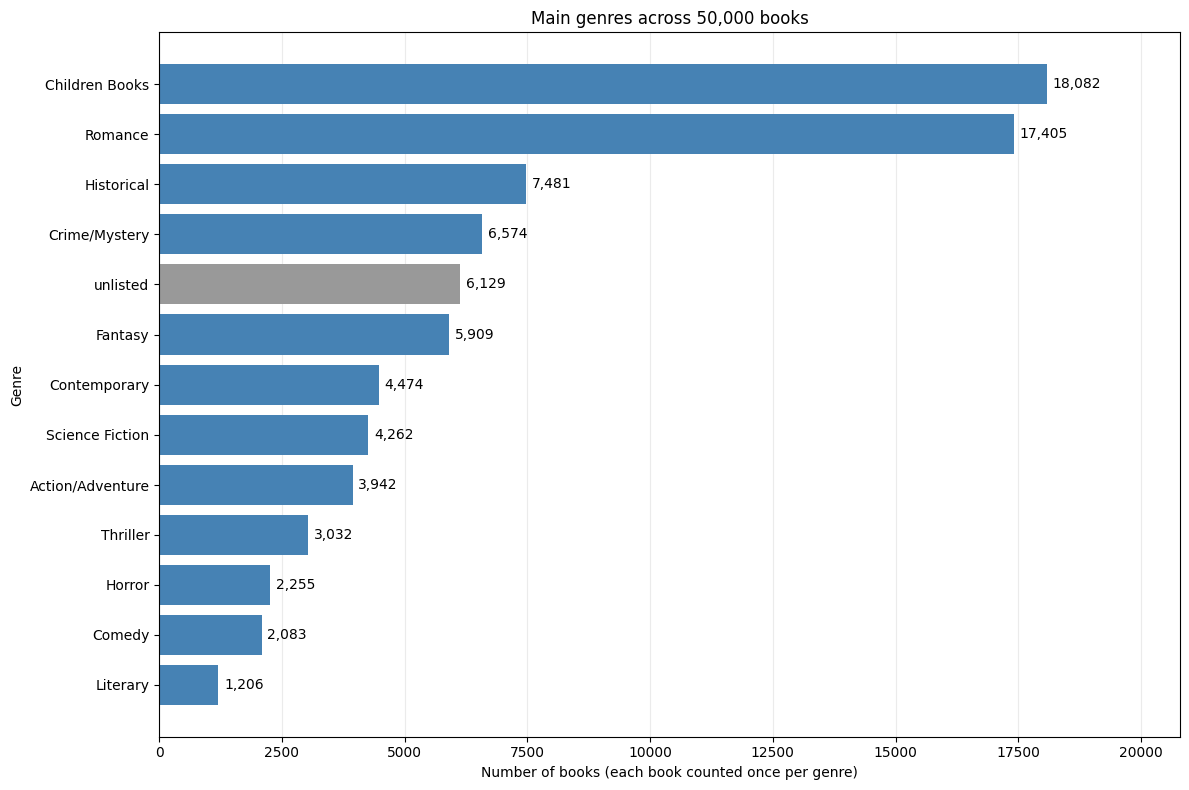

Saved:
data\processed\books_selected_genres.json
data\processed\books_selected_genres.parquet
data\processed\selected_genre_counts.txt
data\processed\selected_genre_popularity.png


In [6]:
import re
import unicodedata
from pathlib import Path

import ftfy
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

PROCESSED_DIR = Path("data/processed")
UNLISTED = "unlisted"
GENRE_PATTERNS = {
    "Crime/Mystery": r"\b(?:crime|mystery)\b",
    "Romance": r"\bromance|romans\b",
    "Fantasy": r"\bfantasy\b",
    "Contemporary": r"\bcontemporary\b",
    "Science Fiction": r"\bscience fiction\b",
    "Action/Adventure": r"\b(?:action|adventure)\b",
    "Horror": r"\bhorror\b",
    "Literary": r"\bliterary\b",
    "Comedy": r"\b(?:comedy|humorous)\b",
    "Children Books": r"\b(?:children|childrens|juvenile)\b",
    "Historical": r"\bhistorical\b",
    "Thriller": r"\b(?:thriller|thrillers)\b",
    
}
GENRE_RULES = {genre: re.compile(pattern) for genre, pattern in GENRE_PATTERNS.items()}
CATALOG_PREFIX = re.compile(r"^(?:collectionid|collection|nyt|series|serie|reading level)\b")


def normalize_genre(label: str) -> str:
    text = ftfy.fix_text(label, normalization="NFKC").casefold()
    text = "".join(ch for ch in text if unicodedata.category(ch) != "Cf")
    text = re.sub(r"['\u2018\u2019]", "", text)
    text = re.sub(r"[^\w\s]|_", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def assign_main_genres(tags: list[str]) -> list[str]:
    """Clean tags first; keep only selected genres on a match, otherwise append unlisted."""
    if not isinstance(tags, list) or any(not isinstance(tag, str) for tag in tags):
        raise TypeError("Each book's genres must be a list of strings.")
    cleaned_tags = list(dict.fromkeys(label for tag in tags if (label := normalize_genre(tag))))
    labels = [label for label in cleaned_tags if not CATALOG_PREFIX.match(label)]
    matches = [
        genre
        for genre, pattern in GENRE_RULES.items()
        if any(pattern.search(label) for label in labels)
    ]
    return matches if matches else list(dict.fromkeys([*cleaned_tags, UNLISTED]))


books = pd.read_json(PROCESSED_DIR / "books.json")
if books.empty:
    raise ValueError("The source book dataset is empty.")
if books["work_key"].isna().any() or books["work_key"].duplicated().any():
    raise ValueError("Expected one non-null, unique work_key per book.")

classified = books.copy()
classified["genres"] = books["genres"].map(assign_main_genres)
counts = (
    classified["genres"].map(lambda tags: list(dict.fromkeys(tags))).explode().value_counts()
    .reindex([*GENRE_RULES, UNLISTED], fill_value=0)
)
json_path = PROCESSED_DIR / "books_selected_genres.json"
parquet_path = PROCESSED_DIR / "books_selected_genres.parquet"
report_path = PROCESSED_DIR / "selected_genre_counts.txt"
chart_path = PROCESSED_DIR / "selected_genre_popularity.png"

classified.to_json(json_path, orient="records", force_ascii=False, indent=2)
classified.to_parquet(parquet_path, engine="pyarrow", index=False)

unlisted_count = int(counts[UNLISTED])
lines = [
    f"Total books: {len(classified):,}",
    f"Books with at least one selected genre: {len(classified) - unlisted_count:,}",
    f"Books with no matching selected genre ({UNLISTED}): {unlisted_count:,}",
    "",
    "Books per genre:",
    *[f"{genre}: {count:,}" for genre, count in counts.items()],
    "",
    "Before matching, tags are lowercased, Unicode-repaired, stripped of punctuation and invisible characters, and whitespace-normalized.",
    "Empty tags and duplicates created by cleaning are removed.",
    "Matching uses normalized category words within existing tags and the explicit mappings below.",
    "Crime or mystery -> Crime/Mystery; action or adventure -> Action/Adventure.",
    "Non-fiction, non fiction, and nonfiction -> Non-fiction.",
    "Children, children's, or juvenile -> Children Books; comedy or humorous -> Comedy.",
    "Catalog metadata tags are ignored when matching selected genres.",
    "Matched books keep only selected genres; all other tags are removed.",
    "Unmatched books retain their cleaned tags and gain unlisted exactly once.",
    "The source books.json and books.parquet files are not modified.",
    "A book can have multiple genres, but counts only once per genre.",
    "Genre counts therefore need not sum to the total number of books.",
]
report = "\n".join(lines) + "\n"
report_path.write_text(report, encoding="utf-8")
print(report)

plot_counts = counts.sort_values(ascending=False, kind="stable")
fig, ax = plt.subplots(figsize=(12, 8))
colors = ["#999999" if genre == UNLISTED else "steelblue" for genre in plot_counts.index]
bars = ax.barh(plot_counts.index, plot_counts.values, color=colors)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{count:,}" for count in plot_counts], padding=4)
ax.set(
    title=f"Main genres across {len(classified):,} books",
    xlabel="Number of books (each book counted once per genre)",
    ylabel="Genre",
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.15)
fig.tight_layout()
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved:\n{json_path}\n{parquet_path}\n{report_path}\n{chart_path}")

In [7]:
from pathlib import Path

import pandas as pd

selected_books = pd.read_json(Path("data/processed/books_selected_genres.json"))
unlisted_books = selected_books.loc[selected_books["genres"].map(lambda tags: "unlisted" in tags)]
unlisted_tags = unlisted_books[["work_key", "genres"]].explode("genres").dropna(subset=["genres"])
unlisted_tags = unlisted_tags.loc[~unlisted_tags["genres"].isin(["unlisted", ""])]
unlisted_tag_counts = (
    unlisted_tags.drop_duplicates(["work_key", "genres"])
    .groupby("genres").size().rename("book_count").reset_index(name="book_count")
    .rename(columns={"genres": "tag"})
    .sort_values(["book_count", "tag"], ascending=[False, True], ignore_index=True)
)
if unlisted_tag_counts.empty:
    raise ValueError("No tags other than 'unlisted' were found among unlisted books.")

highest_count = int(unlisted_tag_counts["book_count"].max())
most_common_unlisted_tags = unlisted_tag_counts.loc[unlisted_tag_counts["book_count"].eq(highest_count)]
print(f"Books labeled unlisted: {len(unlisted_books):,}")
print("Top 20 tags among unlisted books:")
unlisted_tag_counts.head(20)

Books labeled unlisted: 6,129
Top 20 tags among unlisted books:


,tag,book_count
0,fiction,4322
1,fiction general,2411
2,large type books,816
3,fiction in english,416
4,social life and customs,372
5,history,342
6,new york times bestseller,310
7,new york times reviewed,307
8,man woman relationships,298
9,literature,271


Initial book count: 50,000
Removed books with no matching target genre: 6,129
Remaining books with specific genres: 43,871



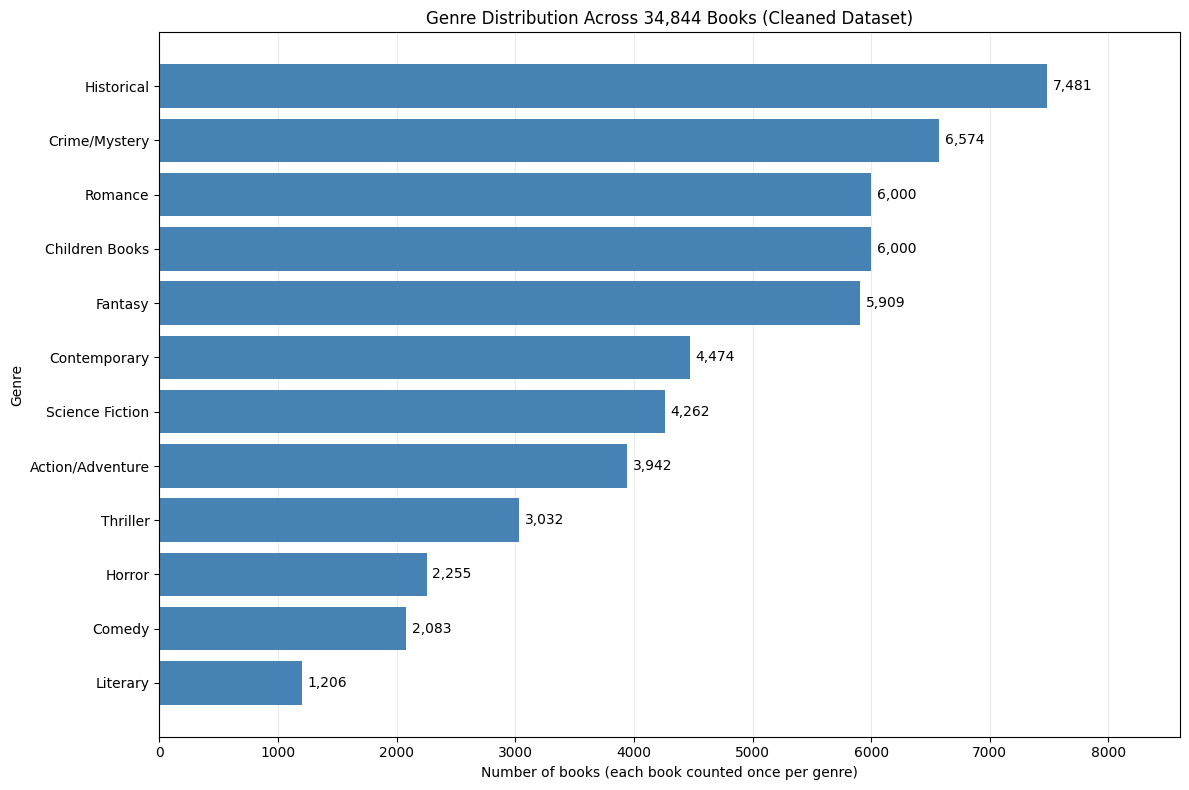

Total books in cleaned dataset: 34,844

Final Genre Counts:
Crime/Mystery: 6,574
Romance: 6,000
Fantasy: 5,909
Contemporary: 4,474
Science Fiction: 4,262
Action/Adventure: 3,942
Horror: 2,255
Literary: 1,206
Comedy: 2,083
Children Books: 6,000
Historical: 7,481
Thriller: 3,032

Final dataset record count: 34,844
Saved visualization to: data\processed\clean_genre_distribution.png


In [11]:
import random
import re
import unicodedata
from pathlib import Path

import ftfy
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

PROCESSED_DIR = Path("data/processed")

GENRE_PATTERNS = {
    "Crime/Mystery": r"\b(?:crime|mystery)\b",
    "Romance": r"\bromance|romans\b",
    "Fantasy": r"\bfantasy\b",
    "Contemporary": r"\bcontemporary\b",
    "Science Fiction": r"\bscience fiction\b",
    "Action/Adventure": r"\b(?:action|adventure)\b",
    "Horror": r"\bhorror\b",
    "Literary": r"\bliterary\b",
    "Comedy": r"\b(?:comedy|humorous)\b",
    "Children Books": r"\b(?:children|childrens|juvenile)\b",
    "Historical": r"\bhistorical\b",
    "Thriller": r"\b(?:thriller|thrillers)\b",
}

GENRE_RULES = {genre: re.compile(pattern) for genre, pattern in GENRE_PATTERNS.items()}
CATALOG_PREFIX = re.compile(r"^(?:collectionid|collection|nyt|series|serie|reading level)\b")

DOMINANT_GENRES = {"Children Books", "Romance"}
TARGET_LIMIT = 6000


def normalize_genre(label: str) -> str:
    text = ftfy.fix_text(label, normalization="NFKC").casefold()
    text = "".join(ch for ch in text if unicodedata.category(ch) != "Cf")
    text = re.sub(r"['\u2018\u2019]", "", text)
    text = re.sub(r"[^\w\s]|_", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def get_matched_genres(tags: list[str]) -> list[str]:
    if not isinstance(tags, list) or any(not isinstance(tag, str) for tag in tags):
        raise TypeError("Each book's genres must be a list of strings.")
    
    cleaned_tags = list(dict.fromkeys(label for tag in tags if (label := normalize_genre(tag))))
    labels = [label for label in cleaned_tags if not CATALOG_PREFIX.match(label)]
    
    matches = [
        genre
        for genre, pattern in GENRE_RULES.items()
        if any(pattern.search(label) for label in labels)
    ]
    return list(dict.fromkeys(matches))


raw_json_path = PROCESSED_DIR / "books.json"
books = pd.read_json(raw_json_path)

books["genres"] = books["genres"].map(get_matched_genres)

has_genre_mask = books["genres"].map(lambda tags: len(tags) > 0)
books_clean = books[has_genre_mask].reset_index(drop=True)

print(f"Initial book count: {len(books):,}")
print(f"Removed books with no matching target genre: {(~has_genre_mask).sum():,}")
print(f"Remaining books with specific genres: {len(books_clean):,}\n")

random.seed(42)
shuffled_indices = list(books_clean.index)
random.shuffle(shuffled_indices)

dominant_counts = {g: 0 for g in DOMINANT_GENRES}
new_genres_dict = {}

for idx in shuffled_indices:
    matched = books_clean.loc[idx, "genres"]
    updated_genres = []
    
    for g in matched:
        if g in DOMINANT_GENRES:
            if dominant_counts[g] < TARGET_LIMIT:
                updated_genres.append(g)
                dominant_counts[g] += 1
        else:
            updated_genres.append(g)
            
    new_genres_dict[idx] = updated_genres

classified = books_clean.copy()
classified["genres"] = classified.index.map(new_genres_dict)

final_mask = classified["genres"].map(lambda tags: len(tags) > 0)
classified = classified[final_mask].reset_index(drop=True)

clean_parquet_path = PROCESSED_DIR / "books_clean_balanced.parquet"
clean_json_path = PROCESSED_DIR / "books_clean_balanced.json"

classified.to_json(clean_json_path, orient="records", force_ascii=False, indent=2)
classified.to_parquet(clean_parquet_path, engine="pyarrow", index=False)

counts = (
    classified["genres"]
    .map(lambda tags: list(dict.fromkeys(tags)))
    .explode()
    .value_counts()
    .reindex(list(GENRE_RULES.keys()), fill_value=0)
)

plot_counts = counts.sort_values(ascending=False, kind="stable")

chart_path = PROCESSED_DIR / "clean_genre_distribution.png"
report_path = PROCESSED_DIR / "clean_genre_counts.txt"

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(plot_counts.index, plot_counts.values, color="steelblue")

ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{count:,}" for count in plot_counts], padding=4)
ax.set(
    title=f"Genre Distribution Across {len(classified):,} Books (Cleaned Dataset)",
    xlabel="Number of books (each book counted once per genre)",
    ylabel="Genre",
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.15)
fig.tight_layout()

fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

lines = [
    f"Total books in cleaned dataset: {len(classified):,}",
    "",
    "Final Genre Counts:",
    *[f"{genre}: {count:,}" for genre, count in counts.items()],
]
report = "\n".join(lines) + "\n"
report_path.write_text(report, encoding="utf-8")

print(report)
print(f"Final dataset record count: {len(classified):,}")
print(f"Saved visualization to: {chart_path}")

# Descriptions cleaning

In [20]:
import pandas as pd

# 1. Wczytanie surowych danych
books = pd.read_json("data/processed/books.json")
books_updated = books.copy()

# 2. Utworzenie nowej kolumny docelowej jako kopii surowych opisów
books_updated["description_updated"] = books_updated["description"].fillna("")

# 3. Wyznaczenie wstępnej liczby słów
books_updated["word_count"] = books_updated["description_updated"].str.split().str.len()

print(f"Łączna liczba książek: {len(books_updated):,}")
print("Brakujące opisy (NaN/puste):", (books_updated["description_updated"] == "").sum())

short_count = (books_updated["word_count"] < 10).sum()
short_pct = (books_updated["word_count"] < 10).mean() * 100
print(f"Opisy poniżej 10 słów: {short_count:,} ({short_pct:.2f}%)")

Łączna liczba książek: 50,000
Brakujące opisy (NaN/puste): 0
Opisy poniżej 10 słów: 676 (1.35%)


In [21]:
import time
import requests
import pandas as pd

# 1. Przygotowanie kolumny docelowej 'desc_cleaned' z kopii surowego opisu
if "desc_cleaned" not in books_updated.columns:
    books_updated["desc_cleaned"] = books_updated["description"].fillna("")

# Obliczenie word_count dla filtrowania
books_updated["word_count"] = books_updated["desc_cleaned"].str.split().str.len()

session = requests.Session()
short_descriptions = books_updated[books_updated["word_count"] < 10]

updated_count = 0
checked_count = 0
errors = 0

print(f"Rozpoczynanie pobierania dla {len(short_descriptions):,} pozycji...")

for index, book in short_descriptions.iterrows():
    edition_keys = book.get("edition_key")

    if isinstance(edition_keys, str):
        edition_keys = [edition_keys]
    elif not isinstance(edition_keys, list):
        continue

    for edition_key in edition_keys:
        if not isinstance(edition_key, str) or not edition_key.strip():
            continue

        url = f"https://openlibrary.org{edition_key if edition_key.startswith('/books/') else '/books/' + edition_key}.json"

        try:
            response = session.get(url, timeout=15)
            checked_count += 1

            if response.status_code != 200:
                errors += 1
                time.sleep(0.1)
                continue

            edition = response.json()
            edition_description = edition.get("description", "")

            if isinstance(edition_description, dict):
                edition_description = edition_description.get("value", "")

            if isinstance(edition_description, str):
                edition_description = edition_description.strip()
                if len(edition_description.split()) > 10:
                    # Zapisujemy do nowej kolumny 'desc_cleaned'
                    books_updated.at[index, "desc_cleaned"] = edition_description
                    updated_count += 1
                    break

            time.sleep(0.1)

        except requests.RequestException:
            errors += 1
            time.sleep(0.1)

    if checked_count > 0 and checked_count % 100 == 0:
        print(f"Sprawdzono wydań: {checked_count} | Zaktualizowano: {updated_count}")

# Przeliczenie słów po uzupełnieniu
books_updated["word_count"] = books_updated["desc_cleaned"].str.split().str.len()

print("\nPODSUMOWANIE UZUPEŁNIANIA API:")
print(f"Sprawdzone wydania: {checked_count}")
print(f"Pomyślnie zaktualizowane opisy: {updated_count}")
print(f"Pozostało opisów < 10 słów: {(books_updated['word_count'] < 10).sum():,}")

# 2. ZAPIS DO PLIKÓW (zachowuje wszystkie oryginalne kolumny + 'desc_cleaned')
# Usuwamy pomocniczą kolumnę word_count przed zapisem (jeśli jej nie chcesz)
df_to_save = books_updated.drop(columns=["word_count"], errors="ignore")

df_to_save.to_parquet("data/processed/books_cleaned.parquet", index=False)
df_to_save.to_json("data/processed/books_cleaned.json", orient="records", indent=2, force_ascii=False)

print("\nZapisano dane ze wszystkimi kolumnami z 'books' + nową 'desc_cleaned' do plików JSON i Parquet.")

Rozpoczynanie pobierania dla 676 pozycji...
Sprawdzono wydań: 100 | Zaktualizowano: 27
Sprawdzono wydań: 200 | Zaktualizowano: 44
Sprawdzono wydań: 300 | Zaktualizowano: 65
Sprawdzono wydań: 400 | Zaktualizowano: 84
Sprawdzono wydań: 500 | Zaktualizowano: 101
Sprawdzono wydań: 600 | Zaktualizowano: 118

PODSUMOWANIE UZUPEŁNIANIA API:
Sprawdzone wydania: 676
Pomyślnie zaktualizowane opisy: 128
Pozostało opisów < 10 słów: 548

Zapisano dane ze wszystkimi kolumnami z 'books' + nową 'desc_cleaned' do plików JSON i Parquet.


In [22]:
import pandas as pd

# 1. Wczytanie pliku
books_updated = pd.read_json("data/processed/books_cleaned.json")

# 2. Wyświetlenie listy kolumn
print(books_updated.columns.tolist())

['work_key', 'title', 'author_name', 'description', 'genres', 'edition_key', 'description_updated', 'desc_cleaned']


In [23]:
import re

# Zachowujemy stan przed zmianą, żeby w kolejnej komórce porównać wyniki
desc_before = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before.copy()

# 1. Odcięcie dolnych sekcji metadanych OpenLibrary
cutoff_patterns = [
    r'\n\s*-{3,}\s*\n',
    r'\n\s*(?:Also contained in|Contains|See also|Followed by|Preceded by)\s*:',
    r'\n\s*\(?\[source\](?:\[\d+\]|\([^)]+\))\)?',
    r'\n\s*\[\d+\]:\s*https?://',
]
combined_cutoff = '|'.join(cutoff_patterns)

s = s.str.split(combined_cutoff, n=1, regex=True).str[0]

# 2. Zamiana linków Markdown w środku tekstu na sam tekst
s = s.str.replace(r'\[([^\]]+)\]\([^)]+\)', r'\1', regex=True)
s = s.str.replace(r'\[([^\]]+)\]\[\d+\]', r'\1', regex=True)

# 3. Usunięcie zbędnych znaków formatowania Markdown
s = s.str.replace(r'^#{1,6}\s+', '', regex=True)
s = s.str.replace('***', '', regex=False).str.replace('**', '', regex=False)

# 4. Porządkowanie białych znaków
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [24]:
changed_mask = desc_before.str.strip() != books_updated["desc_cleaned"]
changed_df = books_updated[changed_mask]

print(f"Zmieniono opisów: {len(changed_df):,}")

sample_df = changed_df.sample(n=min(50, len(changed_df)), random_state=42)

for i, (idx, row) in enumerate(sample_df.iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów: 2,086
PRZYKŁAD 1 | TYTUŁ: The Alexakis Bride
--------------------------------------------------------------------------------
[PRZED]:
***Eligible tycoon seeks perfect bride!***

Damon Alexakis had looks, wealth, power. What he didn't have was a suitable wife....

Kate McKee was the perfect choice. Beautiful, intelligent, she was the adored nanny of his sister's twins; and she was stunned by Damon's proposal! But what choice did she have? To fend off her father's matchmaking efforts, she'd invented a mystery lover -- but would her pretense backfire? The only solution was to accept Damon's extraordinary deal: for one year only, she'd share his life, but not his bed -- at least, that was Kate's interpretation. Damon had other ideas!
----------------------------------------
[PO]:
Eligible tycoon seeks perfect bride!

Damon Alexakis had looks, wealth, power. What he didn't have was a suitable wife....

Kate McKee was the perfect choice. Beautiful, intelligent, she was the

In [27]:
desc_before_prov = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_prov.copy()

# 1. Usunięcie dopisków na końcu opisu typu: "--Provided by publisher.", "-- Provided by the publisher", "-- Container.", "(Provided by publisher)"
s = s.str.replace(
    r'(?i)\s*(?:[-–—]{1,2}\s*|\(\s*)(?:This description comes from (?:the )?publisher|Provided by (?:the )?publisher|Container)\s*\.?\s*\)?\s*$',
    '',
    regex=True
)

# 2. Zdjęcie cudzysłowów okalających cały opis, jeśli po usunięciu "--Provided by publisher." opis zaczyna się i kończy cudzysłowem
has_outer_quotes = s.str.startswith('"') & s.str.endswith('"') & (s.str.count('"') == 2)
s = s.where(~has_outer_quotes, s.str[1:-1])

# 3. Porządkowanie białych znaków
s = s.str.strip()

books_updated["desc_cleaned"] = s

In [30]:
desc_before_extra = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_extra.copy()

# 1. Odcięcie list serii z Goodreads na końcu opisu (np. "Regency Trilogy:\nWicked (Regency Trilogy, #1)...")
s = s.str.replace(
    r'(?i)\n\s*[^\n:]+:\s*(?:\n\s*[^\n]+\([^)]+,\s*#\d+\)\s*)+$',
    '',
    regex=True
)

# 2. Usunięcie pozostałych dopisków wydawców / edycji na końcu (również sklejonych bez spacji po kropce)
s = s.str.replace(
    r'(?i)\s*(?:[-–—]{1,2}\s*)?(?:From (?:the )?(?:publisher description|Hardcover edition|Paperback edition|Trade Paperback edition|Library Binding|back cover)|Provided by (?:the )?publisher)\.?\s*$',
    '',
    regex=True
)

# 3. Usunięcie "From the back cover:" z początku opisu oraz kodów szkolnych typu "(Gr. 2-5 Age 7-10)"
s = s.str.replace(r'(?i)^\s*From the back cover\s*:?\s*', '', regex=True)
s = s.str.replace(r'(?i)^\s*\(Gr\.\s*[\d-]+\s*Age\s*[\d-]+\)\s*', '', regex=True)

# 4. Usunięcie inicjałów i dat katalogowych na końcu (np. "gmb 03-01-20")
s = s.str.replace(r'\s+[a-z]{2,4}\s+\d{2}-\d{2}-\d{2,4}\s*$', '', regex=True)

# 5. Zdjęcie wiszących cudzysłowów i myślników na początku/końcu (np. '"Tekst...--' -> 'Tekst...')
s = s.str.replace(r'^"\s*(.*?)\s*(?:"\s*[-–—]{1,2}|[-–—]{1,2})\s*$', r'\1', regex=True)
# Oraz zwykłych parzystych cudzysłowów wokół całego opisu (nawet jeśli w środku są pojedyncze apostrofy)
has_outer_quotes = s.str.startswith('"') & s.str.endswith('"') & (s.str.count('"') == 2)
s = s.where(~has_outer_quotes, s.str[1:-1])

# 6. Naprawa sklejonych zdań typu "koniec.Początek" -> "koniec. Początek" (z pominięciem skrótów jak U.S. czy J.K.)
s = s.str.replace(r'([a-z]{2,}\.)([A-Z][a-z])', r'\1 \2', regex=True)

# 7. Porządkowanie białych znaków
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [31]:
changed_mask = desc_before_extra.str.strip() != books_updated["desc_cleaned"]
changed_df = books_updated[changed_mask]

print(f"Zmieniono opisów: {len(changed_df):,}")

sample_df = changed_df.sample(n=min(50, len(changed_df)), random_state=42)

for i, (idx, row) in enumerate(sample_df.iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_extra.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów: 4,534
PRZYKŁAD 1 | TYTUŁ: Notes of a crocodile
--------------------------------------------------------------------------------
[PRZED]:
"Set in the post-martial-law era of 1990s Taipei, Notes of a Crocodile depicts the coming-of-age of a group of queer misfits discovering love, friendship, and artistic affinity while hardly studying at Taiwan's most prestigious university. Told through the eyes of an anonymous lesbian narrator nicknamed Lazi, Qiu Miaojin's cult classic novel is a postmodern pastiche of diaries, vignettes, mash notes, aphorisms, exegesis, and satire by an incisive prose stylist and countercultural icon. Afflicted by her fatalistic attraction to Shui Ling, an older woman who is alternately hot and cold toward her, Lazi turns for support to a circle of friends that includes the devil-may-care, rich-kid-turned-criminal Meng Sheng and his troubled, self-destructive gay lover Chu Kuang, as well as the bored, mischievous overachiever Tun Tun and her allurin

In [32]:
wiki_mask = books_updated["desc_cleaned"].str.contains("wikipedia", case=False, na=False)
wiki_df = books_updated[wiki_mask]

print(f"Liczba opisów zawierających słowo 'wikipedia': {len(wiki_df):,}")

for i, (idx, row) in enumerate(wiki_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"{row['desc_cleaned']}\n")

Liczba opisów zawierających słowo 'wikipedia': 114
PRZYKŁAD 1 | TYTUŁ: Crime and Punishment
--------------------------------------------------------------------------------
From wikipedia:

Crime and Punishment (Russian: Преступлéние и наказáние, tr. Prestupleniye i nakazaniye; IPA: \[prʲɪstʊˈplʲenʲə ɪ nəkɐˈzanʲə\]) is a novel by the Russian author Fyodor Dostoyevsky. It was first published in the literary journal The Russian Messenger in twelve monthly installments during 1866.1 It was later published in a single volume. It is the second of Dostoyevsky's full-length novels following his return from ten years of exile in Siberia. Crime and Punishment is considered the first great novel of his "mature" period of writing.\[2\]

Crime and Punishment focuses on the mental anguish and moral dilemmas of Rodion Raskolnikov, an impoverished ex-student in St. Petersburg who formulates and executes a plan to kill an unscrupulous pawnbroker for her cash. Raskolnikov argues that with the pawnbroke

In [33]:
import re

wiki_mask = books_updated["desc_cleaned"].str.contains("wikipedia", case=False, na=False)
print(f"Liczba opisów ze słowem 'wikipedia': {wiki_mask.sum():,}\n")

for i, (idx, text) in enumerate(books_updated.loc[wiki_mask, "desc_cleaned"].head(50).items(), 1):
    # Wyciągamy fragment: 60 znaków przed i 80 po słowie 'wikipedia'
    matches = re.findall(r'.{0,60}wikipedia.{0,80}', text, flags=re.IGNORECASE | re.DOTALL)
    print(f"{i}. [Indeks {idx}]: {repr(matches[0]) if matches else ''}")

Liczba opisów ze słowem 'wikipedia': 114

1. [Indeks 59]: 'From wikipedia:\r\n\r\nCrime and Punishment (Russian: Преступлéние и наказáние, tr. Prestupleniye '
2. [Indeks 67]: "e nation's favourite books from school.\r\n\r\n(From https://en.wikipedia.org/wiki/Lord_of_the_Flies)"
3. [Indeks 102]: 'vel-length version was published in April 1891.\r\n\r\n(Source: Wikipedia)'
4. [Indeks 200]: 'somewhere in Ionia, the Greek coastal region of Anatolia. - Wikipedia'
5. [Indeks 517]: 's, including opposites, time running backwards, and so on. (Wikipedia)'
6. [Indeks 553]: 'y while the beetles, a poodle, and the stunned Fox watch. - Wikipedia.'
7. [Indeks 578]: 'tom of the supposedly "bottomless" Walden Pond.\r\n\r\n(Source: Wikipedia)'
8. [Indeks 756]: "ety. It has proved Wilde's most enduringly popular play. - *Wikipedia*"
9. [Indeks 780]: 's influenced by Charles Dickens’ *Bleak House*.\r\n\r\n(Source: Wikipedia)'
10. [Indeks 879]: 'dvanced Engineering Mathematics is currently available. The W

In [34]:
desc_before_wiki = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_wiki.copy()

# 1. Odcięcie wszystkiego od sekcji źródła Wikipedii w nowej linii w dół (np. "\nSource: Wikipedia", "\n[Wikipedia](https://...)")
s = s.str.replace(
    r'(?i)\n\s*(?:Source\s*:\s*)?(?:\[?Wikipedia\]?(?:\([^)]+\)|\[\d+\])?.*|From Wikipedia, the free encyclopedia\.?.*)$',
    '',
    regex=True
)

# 2. Usunięcie linków/dopisków źródłowych wklejonych na końcu linii (np. "([Wikipedia](https://...))", "(Source: Wikipedia)", "-- Wikipedia")
s = s.str.replace(
    r'(?i)\s*(?:[-–—]{1,2}\s*|\(\s*)(?:Source\s*:\s*)?\[?Wikipedia\]?(?:\([^)]+\)|\[\d+\])?\s*\.?\s*\)?\s*$',
    '',
    regex=True
)

# 3. Usunięcie nagłówka "From Wikipedia, the free encyclopedia." jeśli pojawia się na samym początku opisu
s = s.str.replace(
    r'(?i)^\s*From Wikipedia, the free encyclopedia\.?\s*',
    '',
    regex=True
)

# 4. Zamiana linków Markdown do Wikipedii w środku zdania [jakieś słowo](https://en.wikipedia.org/...) na samo "jakieś słowo"
s = s.str.replace(
    r'\[([^\]]+)\]\(https?://[a-z.]*wikipedia\.org/[^)]+\)',
    r'\1',
    regex=True
)

# 5. Porządkowanie białych znaków
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

# Szybkie sprawdzenie, ile opisów jeszcze zawiera to słowo
remaining_wiki = books_updated["desc_cleaned"].str.contains("wikipedia", case=False, na=False).sum()
print(f"Zmieniono opisów: {(desc_before_wiki.str.strip() != s).sum():,}")
print(f"Pozostało opisów ze słowem 'wikipedia': {remaining_wiki:,}")

Zmieniono opisów: 51
Pozostało opisów ze słowem 'wikipedia': 63


In [35]:
wiki_mask = books_updated["desc_cleaned"].str.contains("wikipedia", case=False, na=False)
wiki_df = books_updated[wiki_mask]

print(f"Liczba opisów zawierających słowo 'wikipedia': {len(wiki_df):,}")

for i, (idx, row) in enumerate(wiki_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"{row['desc_cleaned']}\n")

Liczba opisów zawierających słowo 'wikipedia': 63
PRZYKŁAD 1 | TYTUŁ: Crime and Punishment
--------------------------------------------------------------------------------
From wikipedia:

Crime and Punishment (Russian: Преступлéние и наказáние, tr. Prestupleniye i nakazaniye; IPA: \[prʲɪstʊˈplʲenʲə ɪ nəkɐˈzanʲə\]) is a novel by the Russian author Fyodor Dostoyevsky. It was first published in the literary journal The Russian Messenger in twelve monthly installments during 1866.1 It was later published in a single volume. It is the second of Dostoyevsky's full-length novels following his return from ten years of exile in Siberia. Crime and Punishment is considered the first great novel of his "mature" period of writing.\[2\]

Crime and Punishment focuses on the mental anguish and moral dilemmas of Rodion Raskolnikov, an impoverished ex-student in St. Petersburg who formulates and executes a plan to kill an unscrupulous pawnbroker for her cash. Raskolnikov argues that with the pawnbroker

In [36]:
desc_before_wiki = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_wiki.copy()

# 1. Wyzerowanie opisów będących wyłącznie komentarzem odsyłającym do Wikipedii (Przykład 27)
s = s.str.replace(
    r'(?i)^\s*The description at this Wikipedia entry is pretty close\..*$',
    '',
    regex=True
)

# 2. Usunięcie nagłówków na początku opisu:
# np. "From Wikipedia:", "(From Wikipedia)", "From Wikipedia (emphasis mine):", "Wikipedia\n", "[from Wikipedia:"
s = s.str.replace(
    r'(?i)^\s*[\(\[]?\s*(?:From\s+)?Wikipedia(?:\s*\([^)]+\))?\s*[:\)\]]?\s*',
    '',
    regex=True
)

# 3. Zamiana linków HTML <a href="...wikipedia...">Tekst</a> na sam Tekst (np. Przykład 19, 38, 49)
# Jeśli tekstem linku jest samo "Wikipedia", usuwamy cały tag (wraz z ewentualnym nawiasem wokół niego)
s = s.str.replace(
    r'(?i)\(?\s*<a\s+[^>]*href=["\']?https?://[^"\'>]*wikipedia\.org[^"\'>]*["\']?[^>]*>\s*Wikipedia\s*</a>\s*\)?',
    '',
    regex=True
)
s = s.str.replace(
    r'(?i)<a\s+[^>]*href=["\']?https?://[^"\'>]*wikipedia\.org[^"\'>]*["\']?[^>]*>([^<]+)</a>',
    r'\1',
    regex=True
)

# 4. Usunięcie sekcji "ABOUT AUTHOR: ... --Wikipedia \n Born: ..." (Przykład 16)
s = s.str.replace(
    r'(?i)\n\s*ABOUT AUTHOR\s*:.*$',
    '',
    regex=True
)

# 5. Usunięcie przypisów w nawiasach okrągłych zawierających Wikipedię (np. "(From http://en.wikipedia...)", "(Main source: Wikipedia)", "(description taken from Wikipedia)", "(summary from Wikipedia and the reader)")
s = s.str.replace(
    r'(?i)\s*\([^)]*(?:wikipedia\.org|wikipedia)[^)]*\)\.?',
    '',
    regex=True
)

# 6. Usunięcie akademickiego cytowania Wikipedii w nowej linii (Przykład 31: “Lost at Sea (Comics).” Wikipedia, Wikimedia Foundation...)
s = s.str.replace(
    r'(?i)\n\s*[“"].*?[”"]\s*Wikipedia,\s*Wikimedia Foundation.*$',
    '',
    regex=True
)

# 7. Usunięcie zdań na końcu opisu odsyłających do Wikipedii lub stwierdzających pochodzenie tekstu
# np. "I got this from Wikipedia.", "See more at: http://en.wikipedia...", "More on Wikipedia at...", "Read more at \nhttp://en.wikipedia...", "See the Wikipedia entry for further details..."
s = s.str.replace(
    r'(?i)\s*(?:I got this from Wikipedia|See (?:more|the Wikipedia entry)[^.]*wikipedia[^.]*|More on Wikipedia[^.]*|Read more at\s*https?://[^\s]*wikipedia[^\s]*|From English Wikipedia)\.?\s*$',
    '',
    regex=True
)

# 8. Usunięcie dopisków źródłowych po myślniku lub w osobnej linii na końcu / końcu akapitu
# np. "- *Wikipedia*", "--modified slightly from www.wikipedia.com.", "-- taken from Wikipedia", "- from wikipedia", "Source: Wikipedia.", "--Wikipedia."
s = s.str.replace(
    r'(?i)(?:\s*[-–—]{1,2}\s*|\n\s*[-–—]?\s*)(?:modified slightly from\s+|taken from\s+|from\s+|main source\s*:?\s*|source\s*:?\s*)?\*?(?:www\.)?(?:en\.)?wikipedia(?:\.com|\.org)?\*?\.?',
    '',
    regex=True
)

# 9. Usunięcie gołych adresów URL do Wikipedii doklejonych na końcu tekstu lub zdania (np. Przykład 12, 28)
s = s.str.replace(
    r'(?i)\s*https?://[a-z.]*wikipedia\.org/[^\s)\]]+',
    '',
    regex=True
)

# 10. Zdjęcie nawiasów kwadratowych lub cudzysłowów, jeśli obejmowały cały opis po usunięciu nagłówka (Przykład 17, 25, 41)
s = s.str.strip()
s = s.str.replace(r'^\[(.*)\]$', r'\1', regex=True)
has_outer_quotes = s.str.startswith('"') & s.str.endswith('"') & (s.str.count('"') == 2)
s = s.where(~has_outer_quotes, s.str[1:-1])

# 11. Porządkowanie białych znaków i osieroconych nawiasów/kropek
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [37]:
wiki_mask = books_updated["desc_cleaned"].str.contains("wikipedia", case=False, na=False)
wiki_df = books_updated[wiki_mask]

print(f"Liczba opisów zawierających słowo 'wikipedia': {len(wiki_df):,}")

for i, (idx, row) in enumerate(wiki_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"{row['desc_cleaned']}\n")

Liczba opisów zawierających słowo 'wikipedia': 14
PRZYKŁAD 1 | TYTUŁ: Advanced engineering mathematics
--------------------------------------------------------------------------------
Cited thousands of times in the scholarly literature, this is a seminal work in Engineering Mathematics. First published in 1962, the 2011 tenth edition of Advanced Engineering Mathematics is currently available. The Wikipedia article on the author states it is "the leading textbook for civil, mechanical, electrical, and chemical engineering undergraduate engineering mathematics."
Part of an Open Library list of Classic Engineering Books http://dld.bz/EngClassicsOL

PRZYKŁAD 2 | TYTUŁ: The First Book of Swords
--------------------------------------------------------------------------------
A blend of science fiction and fantasy, the Book of Swords series describes twelve magically swords forged with specific  enhancements, and sometimes serious detracting abilities granted to the one who wields them.  The

In [38]:
# Wzorzec wykrywający zarówno pełne adresy URL (http/https), jak i linki Markdown [tekst](url) lub www.
url_pattern = r'https?://|www\.|\[[^\]]+\]\([^)]+\)'

links_mask = books_updated["desc_cleaned"].str.contains(url_pattern, case=False, na=False, regex=True)
links_df = books_updated[links_mask]

print(f"Liczba opisów zawierających linki: {len(links_df):,} (z {len(books_updated):,})")

for i, (idx, row) in enumerate(links_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"{row['desc_cleaned']}\n")

Liczba opisów zawierających linki: 191 (z 50,000)
PRZYKŁAD 1 | TYTUŁ: Of Mice and Men
--------------------------------------------------------------------------------
The second book in John Steinbeck’s labor trilogy, Of Mice and Men is a touching tale of two migrant laborers in search of work and eventual liberation from their social circumstances. Fiercely devoted to one another, George and Lennie plan to save up to finance their dream of someday owning a small piece of land. The pair seems unstoppable until tragedy strikes and their hopes come crashing down, forcing George to make a difficult decision regarding the welfare of his best friend.

The novel is set on a ranch in Soledad, CA. Author Frank Bergon recalls reading Of Mice and Men for the first time as a teenager living in the San Joaquin Valley and remembers how he saw “as if in a jolt of light the ordinary surroundings of [his] life become worthy of literature.” Steinbeck works to propagate the notion that meaningful storie

In [39]:
desc_before_links = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_links.copy()

# 1. Wyzerowanie opisów, które są tylko duplikatem lub samym przekierowaniem (Przykłady 12, 13, 20, 23, 24, 27, 31, 33)
s = s.str.replace(
    r'(?i)^\s*(?:This is a duplicate\.\s*Please update your lists\.\s*)?See(?:\s+work)?\s*:?\s*<?https?://[^\s>]+>?\s*\.?\s*$',
    '',
    regex=True
)

# 2. Wyciągnięcie właściwego opisu ze zrzutów katalogów bibliotecznych (Przykład 17)
# Jeśli tekst zaczyna się od numeru pozycji bibliotecznej i zawiera "Librarian's View ... Summary\n", bierzemy tekst po ostatnim "Summary\n"
lib_dump_mask = s.str.contains(r"Librarian's View.*?Summary\s*\n", regex=True, na=False)
s = s.where(~lib_dump_mask, s.str.split(r'Summary\s*\n', regex=True).str[-1])

# 3. Usunięcie linków HTML:
# - jeśli link ma tekst "SOURCE" (Przykład 11), usuwamy w całości
s = s.str.replace(r'(?i)\(?\s*<a\s+[^>]*>\s*source\s*</a>\s*\)?', '', regex=True)
# - pozostałe linki HTML <a href="...">Tekst</a> zamieniamy na sam "Tekst" (Przykłady 7, 14, 16, 19, 21, 22, 28, 29, 32, 36)
s = s.str.replace(r'(?i)<a\s+[^>]*>(.*?)</a>', r'\1', regex=True)

# 4. Zamiana linków Markdown [Tekst](url) na sam "Tekst" (np. Przykład 9: [Adventures of Huckleberry Finn] (https://...))
s = s.str.replace(r'\[([^\]]+)\]\s*\(\s*https?://[^)]+\)', r'\1', regex=True)

# 5. Usunięcie spamu "Download..." oraz nagłówków źródłowych z linkiem na początku opisu (Przykłady 10, 18, 25, 26, 35, 37, 39)
s = s.str.replace(
    r'(?i)^\s*(?:Download\s+(?:This\s+Book|on)\s*[➞→-]*\s*https?://\S+|See\s+work\s*:\s*<?https?://\S+>?|\(\s*(?:as\s+taken\s+from|taken\s+from|source)\s*:?[^)]*(?:https?://|www\.)[^)]*\)\s*:?|(?:as\s+taken\s+from|taken\s+from)\s+[^(:\n]+\(\s*(?:https?://|www\.)[^)]+\)\s*:?|https?://\S+\s*:)\s*',
    '',
    regex=True
)

# 6. Usunięcie dopisków na końcu opisu/akapitu zawierających linki (Archive.org, Source:, See more at:, itd.)
s = s.str.replace(
    r'(?i)\s*(?:\(\s*(?:14-day borrow[^)]*|source\s*:?[^)]*)?(?:https?://|www\.)[^)]*\)|\[\s*Also at archive\.org[^\]]*\]|\n?\s*(?:[-–—.]+\s*)?(?:Source|See more at|Part of an Open Library list[^:\n]*|from)\s*:?\s*(?:https?://|www\.)\S+(?:\s*\.\.\.)?)\s*\.?',
    '',
    regex=True
)

# 7. Usunięcie końcówki z Przykładu 34 ("These can be read in the order published... found here: https://...")
s = s.str.replace(
    r'(?i)\s*These can be read in the order published.*?https?://\S+\s*',
    '',
    regex=True
)

# 8. Ostateczne wyczyszczenie wszelkich pozostałych gołych adresów URL (http://..., https://..., www....) wraz z ewentualnymi nawiasami wokół nich
s = s.str.replace(r'(?i)\(?\s*<?(?:https?://|www\.)[^\s<>\)\]]+>?\s*\)?', '', regex=True)

# 9. Zdjęcie wiszących cudzysłowów na brzegach (np. po usunięciu ".... from www.jim-butcher.com ..." w Przykładzie 30)
s = s.str.strip()
s = s.str.replace(r'^"\s*(.*?)\s*"?$', r'\1', regex=True)

# 10. Porządkowanie spacji i pustych linii
s = s.str.replace(r'[ \t]{2,}', ' ', regex=True)
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [40]:
url_pattern = r'https?://|www\.|\[[^\]]+\]\([^)]+\)'
had_links_mask = desc_before_links.str.contains(url_pattern, case=False, na=False, regex=True)
still_has_links = books_updated["desc_cleaned"].str.contains(url_pattern, case=False, na=False, regex=True)

print(f"Opisów z linkami przed: {had_links_mask.sum():,}")
print(f"Pozostało opisów z linkami: {still_has_links.sum():,}\n")

changed_links_df = books_updated[had_links_mask]
for i, (idx, row) in enumerate(changed_links_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_links.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Opisów z linkami przed: 191
Pozostało opisów z linkami: 0

PRZYKŁAD 1 | TYTUŁ: Of Mice and Men
--------------------------------------------------------------------------------
[PRZED]:
The second book in John Steinbeck’s labor trilogy, Of Mice and Men is a touching tale of two migrant laborers in search of work and eventual liberation from their social circumstances. Fiercely devoted to one another, George and Lennie plan to save up to finance their dream of someday owning a small piece of land. The pair seems unstoppable until tragedy strikes and their hopes come crashing down, forcing George to make a difficult decision regarding the welfare of his best friend.

The novel is set on a ranch in Soledad, CA. Author Frank Bergon recalls reading Of Mice and Men for the first time as a teenager living in the San Joaquin Valley and remembers how he saw “as if in a jolt of light the ordinary surroundings of [his] life become worthy of literature.” Steinbeck works to propagate the notion that

In [41]:
import html

desc_before_html = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_html.copy()

# 1. Zamiana znaczników blokowych (<p>, <br>, <div>, <li>, <h1>-<h6>) na znaki nowej linii, żeby akapity się nie skleiły
s = s.str.replace(r'(?i)<\s*(?:br\s*/?|/?(?:p|div|li|h[1-6]|ul|ol|blockquote))\b[^>]*>', '\n', regex=True)

# 2. Usunięcie wszystkich pozostałych znaczników HTML (np. <i>, </i>, <abbr>, <em>, <strong>, <span>)
s = s.str.replace(r'<[^>]+>', '', regex=True)

# 3. Dekodowanie ewentualnych encji HTML (np. &amp; -> &, &quot; -> ", &nbsp; -> spacja, &#39; -> ')
s = s.apply(html.unescape)

# 4. Porządkowanie białych znaków (usunięcie wcięć po usuniętych tagach <p> i nadmiarowych pustych linii)
s = s.str.replace(r'[ \t]+', ' ', regex=True)
s = s.str.replace(r'\n[ \t]+', '\n', regex=True)
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [42]:
changed_html_mask = desc_before_html.str.strip() != books_updated["desc_cleaned"]
changed_html_df = books_updated[changed_html_mask]

print(f"Zmieniono opisów ze znacznikami/encjami HTML: {len(changed_html_df):,}")

sample_df = changed_html_df.sample(n=min(50, len(changed_html_df)), random_state=42)

for i, (idx, row) in enumerate(sample_df.iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_html.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów ze znacznikami/encjami HTML: 1,320
PRZYKŁAD 1 | TYTUŁ: Call It Destiny
--------------------------------------------------------------------------------
[PRZED]:
Her perfect arrangement left out love

 Beautiful impetuous Heather Strand had big plans for running the family's Tucson resort. And one in particular was quite unorthodox. She wanted a marriage of convenience with devilishly handsome Jake Lavender, her father's right-hand man!

 A prenuptial contract spelled out all the details--or so Heather thought. But it didn't cover passion, something she felt when Jake's hot velvet mouth descended on hers. Nor did it mention desire, which is what coursed through her body as they hungrily made love ....
----------------------------------------
[PO]:
Her perfect arrangement left out love

Beautiful impetuous Heather Strand had big plans for running the family's Tucson resort. And one in particular was quite unorthodox. She wanted a marriage of convenience with devilishly h

In [43]:
desc_before_web = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_web.copy()

# 1. Jeśli opis ma nagłówek "Synopsis" w osobnej linii (np. po "This book is part of a series:..."), bierzemy wszystko od "Synopsis" w dół
has_synopsis = s.str.contains(r'(?im)^(?:This book is part of a series:.*\n)?\s*Synopsis\s*\n', regex=True)
s = s.where(~has_synopsis, s.str.split(r'(?im)^\s*Synopsis\s*\n', n=1, regex=True).str[-1])

# 2. Odcięcie wszystkiego od sekcji technicznych strony w dół (Details, Excerpt, Dedication, stopki WWW)
web_cutoff_patterns = [
    r'\n\s*Details\s*\n\s*(?:First Published|Publisher|ISBN)\s*:',
    r'\n\s*Excerpt\s*\n',
    r'\n\s*Dedication\s*\n',
    r'\n\s*Privacy Policy\s*\|\s*Cookie',
    r'\n\s*©\s*.*All Rights Reserved\.?',
]
combined_web_cutoff = '(?i)' + '|'.join(web_cutoff_patterns)

s = s.str.split(combined_web_cutoff, n=1, regex=True).str[0]

# 3. Porządkowanie białych znaków
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [44]:
changed_web_mask = desc_before_web.str.strip() != books_updated["desc_cleaned"]
changed_web_df = books_updated[changed_web_mask]

print(f"Zmieniono opisów ze zrzutami stron WWW / Excerpt / Details: {len(changed_web_df):,}")

for i, (idx, row) in enumerate(changed_web_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    # Skracamy [PRZED] w podglądzie do 600 znaków, żeby ogromne rozdziały nie zalały ekranu
    before_preview = desc_before_web.at[idx]
    if len(before_preview) > 600:
        before_preview = before_preview[:300] + "\n\n[... WYCIĘTY ŚRODEK ...]\n\n" + before_preview[-300:]
    print(f"[PRZED]:\n{before_preview}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów ze zrzutami stron WWW / Excerpt / Details: 4
PRZYKŁAD 1 | TYTUŁ: Fatherland
--------------------------------------------------------------------------------
[PRZED]:
Fatherland is set in a world that almost existed but never was: the Berlin that Hitler's architect, Albert Speer, planned to build- the hub of a victorious Third Reich extending from the Rhine to the Urals.

Synopsis

Expand/Collapse Synopsis
It is April 1964 and one week before Hitler's 75th b

[... WYCIĘTY ŚRODEK ...]

t could go to the very top of the German Reich. And, with the Gestapo just one step behind, March, together with an American journalist, is caught up in a race to discover and reveal the truth - a truth that has already killed, a truth that could topple governments, a truth that will change history.
----------------------------------------
[PO]:
Expand/Collapse Synopsis
It is April 1964 and one week before Hitler's 75th birthday. Xavier March, a detective of the Kriminalpolizei, is called 

In [45]:
desc_before_cont = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_cont.copy()

# Wyzerowanie opisów zaczynających się od "Contains:" lub "Also contained in:" (spis zawartości wydania zbiorczego bez opisu fabuły)
is_only_contents = s.str.match(r'(?i)^\s*(?:Contains|Also contained in|Contents)\s*:', na=False)
s = s.where(~is_only_contents, "")

books_updated["desc_cleaned"] = s

In [46]:
changed_cont_mask = desc_before_cont.str.strip() != books_updated["desc_cleaned"]
changed_cont_df = books_updated[changed_cont_mask]

print(f"Wyzerowano opisów będących wyłącznie listą 'Contains:': {len(changed_cont_df):,}")

for i, (idx, row) in enumerate(changed_cont_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_cont.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{repr(row['desc_cleaned'])}\n")

Wyzerowano opisów będących wyłącznie listą 'Contains:': 161
PRZYKŁAD 1 | TYTUŁ: The Complete Sherlock Holmes
--------------------------------------------------------------------------------
[PRZED]:
Contains:

- Adventures of Sherlock Holmes

Scandal in Bohemia
Red-Headed League
Case of Identity
Boscombe Valley Mystery
Five Orange Pips
Man with the Twisted Lip
Adventure of the Blue Carbuncle
Adventure of the Speckled Band
Adventure of the Engineer's Thumb
Adventure of the Noble Bachelor
Adventure of the Beryl Coronet
Adventure of the Copper Beeches

- Case-Book of Sherlock Holmes
- His Last Bow
- Hound of the Baskervilles
- Memoirs of Sherlock Holmes [11 stories]

Silver Blaze
Adventure of the Yellow Face
Adventure of the Stockbroker's Clerk
Adventure of the Gloria Scott
Adventure of the Musgrave Ritual
Adventure of the Reigate Squire
Crooked Man
Adventure of the Resident Patient
Adventure of the Greek Interpreter
Naval Treaty
Final Problem

- Return of Sherlock Holmes

Adventure of th

In [50]:
desc_before_series = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_series.copy()

# 1. Odcięcie dolnej listy tomów po nagłówku zakończonym dwukropkiem (np. "St. James Family:\nMistress of the Night\nNightfire")
# Łapie sytuację, gdy po pustej linii pojawia się krótki nagłówek z dwukropkiem, a pod nim 2+ krótkich linii (tytułów) aż do końca tekstu
s = s.str.replace(
    r'\n\s*\n[A-Z][^\n:]{2,50}:\s*(?:\n[^\n.!?]{2,60}){2,}\s*$',
    '',
    regex=True
)

# 2. Usunięcie nagłówka z nazwą serii i numerem tomu na samej górze (np. "St. James Family #1\n\n")
s = s.str.replace(
    r'^[A-Z][^\n]{2,50}#\d+\s*\n+',
    '',
    regex=True
)

s = s.str.strip()
books_updated["desc_cleaned"] = s

In [51]:
changed_series_mask = desc_before_series.str.strip() != books_updated["desc_cleaned"]
changed_series_df = books_updated[changed_series_mask]

print(f"Zmieniono opisów: {len(changed_series_df):,}")

for i, (idx, row) in enumerate(changed_series_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_series.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów: 290
PRZYKŁAD 1 | TYTUŁ: Hearts in Atlantis
--------------------------------------------------------------------------------
[PRZED]:
Hearts in Atlantis (1999) is a collection of two novellas and three short stories by Stephen King, all connected to one another by recurring characters and taking place in roughly chronological order.

The stories are about the Baby Boomer Generation, specifically King's view that this generation (to which he belongs) failed to live up to its promise and ideals. Significantly, the opening epigraph of the collection is the Peter Fonda line from the end of Easy Rider: "We blew it." All of the stories are about the 1960s and the war in Vietnam, and in all of them the members of that generation fail profoundly, or are paying the costs of some profound failure on their part.

In this collection:

- Blind Willie
- Hearts in Atlantis
- Heavenly Shades of Night Are Falling
- Low Men in Yellow Coats
- Why We're in Vietnam
------------------------

In [52]:
desc_before_final = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_final.copy()

# 1. Wyzerowanie notatek technicznych o skanach / brakujących stronach (np. OPIS 85)
is_scan_note = s.str.contains(r'(?i)The photocopy of this edition is missing|This edition is readable; it contains all pages', regex=True, na=False)
s = s.where(~is_scan_note, "")

# 2. Usunięcie pozostałych końcówek źródłowych po myślniku (Publisher, Dust jacket, Back cover, Amazon.com, Publisher's description/website)
s = s.str.replace(
    r'(?i)\s*"?\s*[-–—]{1,2}\s*(?:Publisher(?:\'s\s+(?:description|website))?|Dust\s+jacket|Back\s+cover|Amazon\.com)\s*\.?\s*$',
    '',
    regex=True
)

# 3. Usunięcie maskowanych źródeł na początku typu "From annabookbel dot net: "
s = s.str.replace(r'(?i)^\s*From\s+[a-z0-9-]+\s+dot\s+(?:com|net|org|uk)\s*:\s*"?\s*', '', regex=True)

# 4. Zdjęcie wiszących cudzysłowów na początku/końcu po odcięciu końcówek
s = s.str.strip()
s = s.str.replace(r'^"\s*(.*?)\s*"?$', r'\1', regex=True)

# 5. Usunięcie przypisów liczbowych typu [1], [2], [12]
s = s.str.replace(r'\[\d+\]', '', regex=True)

# 6. Usunięcie znaku '>' użytego jako separator w środku tekstu (OPIS 95) i naprawa spacji po ! i ?
s = s.str.replace(r'([.!?])\s*>\s*([A-Z])', r'\1 \2', regex=True)
s = s.str.replace(r'([a-z]{2,}[!?])([A-Z][a-z])', r'\1 \2', regex=True)

# 7. Usunięcie identycznych zduplikowanych akapitów w obrębie jednego opisu (OPIS 26)
def deduplicate_paragraphs(text):
    if not text or "\n" not in text:
        return text
    seen = set()
    unique_paras = []
    for para in text.split("\n"):
        norm = para.strip()
        if not norm:
            unique_paras.append("")
            continue
        if norm not in seen:
            seen.add(norm)
            unique_paras.append(para)
    return "\n".join(unique_paras)

s = s.apply(deduplicate_paragraphs)

# 8. Porządkowanie białych znaków
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [53]:
changed_final_mask = desc_before_final.str.strip() != books_updated["desc_cleaned"]
changed_final_df = books_updated[changed_final_mask]

print(f"Zmieniono opisów: {len(changed_final_df):,}")

sample_df = changed_final_df.sample(n=min(50, len(changed_final_df)), random_state=42)

for i, (idx, row) in enumerate(sample_df.iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_final.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów: 5
PRZYKŁAD 1 | TYTUŁ: The Lady Forfeits
--------------------------------------------------------------------------------
[PRZED]:
"Lady Diana Copeland has hot-footed it to London to tell her new guardian, Lord Faulkner, exactly what she thinks of his outrageous marriage demands! Well, with her two flighty sisters having run off, no one else is going to do it ... . Surely this magnificent man with a naughty glint in his eye can't be the pompous old fool she was expecting? Inhaling deeply, Diana fights not to get lost in the depths of Lord Faulkner's intoxicating gaze ... or to make the worst forfeit--by agreeing to be the lord's new countess!"--Publisher.
----------------------------------------
[PO]:
Lady Diana Copeland has hot-footed it to London to tell her new guardian, Lord Faulkner, exactly what she thinks of his outrageous marriage demands! Well, with her two flighty sisters having run off, no one else is going to do it ... . Surely this magnificent man with a n

In [54]:
desc_before_nested = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_nested.copy()

# Odcięcie wszystkiego od nagłówka serii (wiersz zakończony ':') w dół, jeśli po nim występuje pozycja z numerem typu "(Seria, #1)" lub "(Seria, #3.5)"
s = s.str.replace(
    r'\n[^\n:]+:\s*\n[^\n]+\([^)]+,\s*#\d+(?:\.\d+)?\)[\s\S]*$',
    '',
    regex=True
)

s = s.str.strip()
books_updated["desc_cleaned"] = s

In [55]:
changed_nested_mask = desc_before_nested.str.strip() != books_updated["desc_cleaned"]
changed_nested_df = books_updated[changed_nested_mask]

print(f"Zmieniono opisów: {len(changed_nested_df):,}")

for i, (idx, row) in enumerate(changed_nested_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_nested.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów: 65
PRZYKŁAD 1 | TYTUŁ: Whitney, My Love
--------------------------------------------------------------------------------
[PRZED]:
Note: 1985 is the Original, unedited version

Fresh from her triumphs in Paris society, Whitney Stone returns to England determined to win the heart of her childhood love. However, in order to save himself from ruin, her father has come to an arrangement with the arrogant Duke of Claymore, and Whitney is the price.

Characters from the Westmoreland Dynasty Saga universe appear across the novels. From this era, Whitney, Clayton, and Stephen appear in Until You, with Clayton and Stephen's ancestor, Royce Westmoreland, as the main character in A Kingdom of Dreams.
If you'd like to read in order: 
A Kingdom of Dreams (Westmoreland, #1)
Once and Always (Sequels, #1)
Something Wonderful (Sequels, #2)
Almost Heaven (Sequels, #3)
Whitney, My Love (Westmoreland, #2)
Until You (Westmoreland, #3)
Miracles (Westmoreland, #3.5) 
The following Contain "M

In [57]:
desc_before_polish = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_polish.copy()

# 1. Wyzerowanie opisów będących wyłącznie listą tytułów zakończonych " --" (np. OPIS 73: Sherlock Holmes)
is_only_toc_dashes = s.str.match(r'^\s*(?:[^\n]+--\s*\n){2,}[^\n]+\.?\s*$', na=False)
s = s.where(~is_only_toc_dashes, "")

# 2. Usunięcie bibliotekarskiego dopisku "--P. 4 of cover." (oraz p. 4 of cover / page 4 of cover)
s = s.str.replace(
    r'(?i)\s*"?\s*[-–—]{1,2}\s*(?:p\.?|page)\s*4\s+of\s+cover\.?\s*$',
    '',
    regex=True
)

# 3. Usunięcie sekcji "E-book exclusives: ..." jeśli pojawia się na początku przed właściwym opisem (OPIS 86)
s = s.str.replace(
    r'(?i)^\s*E-book exclusives\s*:.*?(?=(?:Sheriff|Detective|Inspector|When|In\s+the|A\s+terrifying|[A-Z][a-z]+\s+[A-Z][a-z]+,\s+working))',
    '',
    regex=True
)

# 4. Usunięcie samotnego cudzysłowu na początku opisu, jeśli w całym tekście jest tylko 1 cudzysłów (OPIS 89)
single_quote_start = (s.str.count('"') == 1) & s.str.match(r'^[^"\n]{1,60}"', na=False)
s = s.where(~single_quote_start, s.str.replace('"', '', n=1, regex=False))

# 5. Porządkowanie białych znaków
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [58]:
changed_polish_mask = desc_before_polish.str.strip() != books_updated["desc_cleaned"]
changed_polish_df = books_updated[changed_polish_mask]

print(f"Zmieniono opisów: {len(changed_polish_df):,}")

for i, (idx, row) in enumerate(changed_polish_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_polish.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{repr(row['desc_cleaned']) if row['desc_cleaned'] == '' else row['desc_cleaned']}\n")

Zmieniono opisów: 365
PRZYKŁAD 1 | TYTUŁ: The Girl in Room 105
--------------------------------------------------------------------------------
[PRZED]:
Zara and I broke up four years ago. She moved on in life. I didn't. I drank every night to forget her. I called, messaged, and stalked her on social media. She just ignored me. However, that night, on the eve of her birthday, Zara messaged me. She called me over, like old times, to her hostel room 105. I shouldn't have gone, but I did ... and my life changed forever. This is not a love story. It is an unlove story."--Page 4 of cover.
----------------------------------------
[PO]:
Zara and I broke up four years ago. She moved on in life. I didn't. I drank every night to forget her. I called, messaged, and stalked her on social media. She just ignored me. However, that night, on the eve of her birthday, Zara messaged me. She called me over, like old times, to her hostel room 105. I shouldn't have gone, but I did ... and my life changed f

In [60]:
desc_before_final2 = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_final2.copy()

# 1. Wyzerowanie metryczek fizycznych typu "315 pages (large print) ; 25 cm" (OPIS 22)
is_physical_desc = s.str.match(r'(?i)^\s*\d+\s*pages?\b.*(?:\bcm\b|\bin\.?\b|large print)\s*$', na=False)
s = s.where(~is_physical_desc, "")

# 2. Usunięcie końcówek po myślniku: --Cover, - Jacket flap., -Google Books, ---- originally published as... (OPIS 6, 32, 38, 81)
s = s.str.replace(
    r'(?i)(?:\s*"?\s*[-–—]{1,4}\s*|\n\s*[-–—]{1,4}\s*)(?:Cover|Jacket\s+flap|Google\s+Books|originally\s+published\s+as\s+[^\n]+)\.?\s*$',
    '',
    regex=True
)

# 3. Usunięcie notatki bibliotecznej "Suggested level: ..." na końcu opisu (OPIS 75)
s = s.str.replace(r'(?i)\s*Suggested level\s*:[^.\n]+\.?\s*$', '', regex=True)

# 4. Usunięcie wielokropka na samym początku opisu (OPIS 79: ". . . A sweeping...")
s = s.str.replace(r'^\s*(?:\.\s*){3,}', '', regex=True)

# 5. Naprawa sklejonego słowa przed nazwą kraju/miejsca typu "seriesEngland" (OPIS 49)
s = s.str.replace(r'([a-z]{3,})([A-Z][a-z]{2,})', r'\1 \2', regex=True)

# 6. Porządkowanie białych znaków
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [61]:
changed_mask = desc_before_final2.str.strip() != books_updated["desc_cleaned"]
print(f"Zmieniono w tym kroku: {changed_mask.sum():,}")

for i, (idx, row) in enumerate(books_updated[changed_mask].head(30).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_final2.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{repr(row['desc_cleaned']) if row['desc_cleaned'] == '' else row['desc_cleaned']}\n")

Zmieniono w tym kroku: 809
PRZYKŁAD 1 | TYTUŁ: The Love Hypothesis
--------------------------------------------------------------------------------
[PRZED]:
The Instant New York Times Best Seller and TikTok Sensation!

As seen on The View!

A BuzzFeed Best Summer Read of 2021

When a fake relationship between scientists meets the irresistible force of attraction, it throws one woman's carefully calculated theories on love into chaos.

As a third-year PhD candidate, Olive Smith doesn't believe in lasting romantic relationships—but her best friend does, and that's what got her into this situation. Convincing Anh that Olive is dating and well on her way to a happily ever after was always going to take more than hand-wavy Jedi mind tricks: Scientists require proof. So, like any self-respecting biologist, Olive panics and kisses the first man she sees.

That man is none other than Adam Carlsen, a young hotshot professor—and well-known ass. Which is why Olive is positively floored when Stanf

In [62]:
desc_before_toc = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_toc.copy()

# Liczymy ile w danym opisie jest linii w formacie katalogowym: "Tytuł / Autor" (bez kropki na końcu linii)
slash_author_lines = s.str.count(r'(?m)^[^\n.!?]+ / [A-Z][^\n]+$')

# Wyzerowanie opisów, które składają się głównie z takiej listy utworów (np. >= 3 pozycje "Tytuł / Autor")
is_toc_slash_list = slash_author_lines >= 3
s = s.where(~is_toc_slash_list, "")

books_updated["desc_cleaned"] = s

In [63]:
changed_toc_mask = desc_before_toc.str.strip() != books_updated["desc_cleaned"]
changed_toc_df = books_updated[changed_toc_mask]

print(f"Wyzerowano opisów będących spisem treści (Tytuł / Autor): {len(changed_toc_df):,}")

for i, (idx, row) in enumerate(changed_toc_df.head(50).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_toc.at[idx][:300]}...")
    print("-" * 40)
    print(f"[PO]:\n{repr(row['desc_cleaned'])}\n")

Wyzerowano opisów będących spisem treści (Tytuł / Autor): 48
PRZYKŁAD 1 | TYTUŁ: The Crucible
--------------------------------------------------------------------------------
[PRZED]:
Crucible / Arthur Miller 
Conversation with an American writer / Yevgeny Yevtushenko 
Guilt / Clifford Lindsey Alderman 
How to spot a witch / Adam Goodheart 
Young Goodman Brown / Nathaniel Hawthorne 
Great Fear / J. Ronald Oakley 
Justice Denied in Massachusetts / Edna St. Vincent Millay 
V...
----------------------------------------
[PO]:
''

PRZYKŁAD 2 | TYTUŁ: Great Short Stories of the World
--------------------------------------------------------------------------------
[PRZED]:
The leader of the people / John Steinbeck 
Mr. Know-all / W. Somerset Maugham 
Vanka / Anton Chekhov 
The happy prince / Oscar Wilde 
The old demon / Pearl S. Buck 
The sailor-boy's tale / Isak Dinesen 
Young Archimedes / Aldous Huxley 
Butch minds the baby / Damon Runyon 
Suspicion / Doroth...
-----------------------------

In [66]:
desc_before_gr = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_gr.copy()

# 1. Usunięcie pełnego nagłówka zeskrobanego ze strony Goodreads (OPIS 45: Tytuł, seria, "by Autor (Goodreads Author)", "3.68 · Rating details...")
s = s.str.replace(
    r'(?is)^[\s\S]{0,250}?\b\d\.\d{2}\s*·\s*Rating details\s*·[^\n]+\n+',
    '',
    regex=True
)

# 2. Odcięcie recenzji użytkowników Goodreads z datą i oceną na dole (OPIS 15: "GOODREADS Review:\nFeb 15, 2018 Candace rated it...")
s = s.str.replace(
    r'(?is)\n\s*GOODREADS Review\s*:[\s\S]*$',
    '',
    regex=True
)

# 3. Usunięcie nagłówków źródłowych na początku opisu lub przed akapitem:
# "From Goodreads:", "(From Goodreads):", "From book description on Goodreads:", "Goodreads Review:", "(As described on goodreads)"
s = s.str.replace(
    r'(?im)^\s*\(?\s*(?:From\s+(?:book\s+description\s+on\s+)?Goodreads|As\s+described\s+on\s+goodreads|Goodreads\s+Review)\s*\)?\s*:?\s*',
    '',
    regex=True
)

# 4. Usunięcie etykietek w środku lub na początku linii: "(goodreads review)", "(goodreads)", "goodreads review:", "goodreads:"
s = s.str.replace(
    r'(?im)(?:^|\s)\(\s*goodreads(?:\s+review)?\s*\)\s*:?\s*|\bgoodreads(?:\s+review)?\s*:\s*',
    ' ',
    regex=True
)

# 5. Usunięcie dopisków na końcu opisu lub akapitu:
# "(goodreads.com)", "(copied from goodreads.com)", "[Aneca-Goodreads]", "*--goodreads", "--Goodreads", "- Goodreads.com", "from Goodreads", "--Autor (goodreads reviewer)"
s = s.str.replace(
    r'(?im)\s*(?:\(\s*(?:copied\s+from\s+)?goodreads(?:\.com)?\s*\)|\[\s*[^\]]*goodreads[^\]]*\s*\]|\*?\s*[-–—]{1,2}\s*(?:From\s+)?goodreads(?:\.com)?\.?|\*?\s*[-–—]{1,2}\s*[^\n(]+\(goodreads(?:\s+reviewer)?\)|(?:\n|^)\s*(?:from\s+)?goodreads(?:\.com)?\.?)\s*$',
    '',
    regex=True
)

# 6. Porządkowanie ewentualnych wiszących cudzysłowów wokół całego opisu oraz białych znaków
s = s.str.strip()
s = s.str.replace(r'^["“]\s*([\s\S]*?)\s*["”]$', r'\1', regex=True)
s = s.str.replace(r'[ \t]{2,}', ' ', regex=True)
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [67]:
changed_gr_mask = desc_before_gr.str.strip() != books_updated["desc_cleaned"]
print(f"Zmieniono opisów w tym kroku: {changed_gr_mask.sum():,}")

gr_after_mask = books_updated["desc_cleaned"].str.contains("goodreads", case=False, na=False)
print(f"Pozostało opisów ze słowem 'goodreads': {gr_after_mask.sum():,}\n")

for i, (idx, row) in enumerate(books_updated[changed_gr_mask].head(30).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów w tym kroku: 396
Pozostało opisów ze słowem 'goodreads': 34

PRZYKŁAD 1 | TYTUŁ: Percy Jackson and the Greek Gods
--------------------------------------------------------------------------------
[PO]:
A publisher in New York asked me to write down what I know about the Greek gods, and I was like, 'Can we do this anonymously?' Because I don't need the Olympians mad at me again. But if it helps you to know your Greek gods, and survive an encounter with them if they ever show up in your face, then I guess writing all this down will be my good deed for the week."

So begins Percy Jackson's Greek Gods, in which the son of Poseidon adds his own magic - and sarcastic asides - to the classics. He explains how the world was created, then gives listeners his personal take on a who's who of ancients, from Apollo to Zeus. Percy does not hold back: "If you like horror shows, blood baths, lying, stealing, backstabbing, and cannibalism, then read on, because it definitely was a Golde

In [68]:
# Wzorzec szukający nawiasów określających wiek lub poziom szkolny (np. "(Age 3-7...)", "(Ages 4 to 8)", "(Grades 1-3)")
age_pattern = r'\(\s*(?:Ages?|Grades?)\s*\d+[^)]*\)'

age_mask = books_updated["desc_cleaned"].str.contains(age_pattern, case=False, na=False, regex=True)
age_df = books_updated[age_mask]

print(f"Liczba opisów zawierających dopiski wiekowe/szkolne w nawiasach: {len(age_df):,}\n")

for i, (idx, row) in enumerate(age_df.head(30).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"{row['desc_cleaned']}\n")

Liczba opisów zawierających dopiski wiekowe/szkolne w nawiasach: 11

PRZYKŁAD 1 | TYTUŁ: Black Beauty
--------------------------------------------------------------------------------
(Ages 9-12, Gr. 4-7) An animal rights classic that's also an engaging read, BLACK BEAUTY follows the life of an ebony horse from birth to old age, and from pasture to the cobblestone streets of 19th century England This morality tale and animal "autobiography" gives a sweet and kind horse a voice that's relatable yet unsentimental.. Black Beauty's life begins on the grounds of an aristocratic English family. The young horse learns early lessons from his mother like how not to bite or kick even in play before circumstances force his sale to a new master; it's the first of several such sales/moves for the horse. As his life intersects with different human owners, caretakers, and neighbors, Black Beauty experiences different kinds of care and abuse, and he observes the differing attitudes of humans toward hor

In [69]:
desc_before_age = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_age.copy()

# 1. Usunięcie dopisków recenzentów Amazon.com przed nawiasem wiekowym (Przykład 3)
s = s.str.replace(r'(?i)\(\s*Amazon\.com\s+Review\s*--[^)]+\)\s*', '', regex=True)

# 2. Usunięcie nawiasów wiekowych i szkolnych wraz z ewentualną gwiazdką po nawiasie oraz dopiskiem "--This text refers to..." lub "--Autor \n Review" (Przykłady 1-11)
s = s.str.replace(
    r'(?i)\s*\(\s*(?:Ages?|Grades?|Preschool|Pre-K|Kindergarten)\s*[^)]*\)\s*\*?(?:\s*[-–—]{1,2}\s*(?:This text refers to[^\n.]+|[A-Z][a-z]+\s+[A-Z][a-z]+(?:\s*\n\s*Review)?)\.?)?',
    ' ',
    regex=True
)

# 3. Usunięcie ewentualnego drugiego nawiasu obok (np. "(Age 4-8) (Preschool to Gr 3)" -> zostaje "(Preschool to Gr 3)", Przykłady 4 i 5)
s = s.str.replace(
    r'(?i)\s*\(\s*(?:Preschool|Pre-K|Gr\.?|Grades?)\s*[^)]*\)\s*',
    ' ',
    regex=True
)

# 4. Usunięcie śmieciowej stopki z Przykładu 1 ("strong text author: a person who wrote the book")
s = s.str.replace(r'(?im)\n*\s*strong text author:.*$', '', regex=True)

# 5. Porządkowanie białych znaków i pustych linii
s = s.str.replace(r'[ \t]{2,}', ' ', regex=True)
s = s.str.replace(r'\n[ \t]+', '\n', regex=True)
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [70]:
changed_age_mask = desc_before_age.str.strip() != books_updated["desc_cleaned"]
print(f"Zmieniono opisów: {changed_age_mask.sum():,}\n")

for i, (idx, row) in enumerate(books_updated[changed_age_mask].head(30).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_age.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Zmieniono opisów: 23

PRZYKŁAD 1 | TYTUŁ: Black Beauty
--------------------------------------------------------------------------------
[PRZED]:
(Ages 9-12, Gr. 4-7) An animal rights classic that's also an engaging read, BLACK BEAUTY follows the life of an ebony horse from birth to old age, and from pasture to the cobblestone streets of 19th century England This morality tale and animal "autobiography" gives a sweet and kind horse a voice that's relatable yet unsentimental.. Black Beauty's life begins on the grounds of an aristocratic English family. The young horse learns early lessons from his mother like how not to bite or kick even in play before circumstances force his sale to a new master; it's the first of several such sales/moves for the horse. As his life intersects with different human owners, caretakers, and neighbors, Black Beauty experiences different kinds of care and abuse, and he observes the differing attitudes of humans toward horses. Peppered throughout the novel are

In [72]:
before_count = len(books_updated)

# Usunięcie rekordów z pustym opisem lub NaN po czyszczeniu
books_updated = books_updated[
    books_updated["desc_cleaned"].notna() & 
    (books_updated["desc_cleaned"].str.strip() != "")
].reset_index(drop=True)

after_count = len(books_updated)
print(f"Liczba rekordów przed: {before_count:,}")
print(f"Usunięto pustych rekordów: {before_count - after_count:,}")
print(f"Pozostało czystych rekordów: {after_count:,}")

Liczba rekordów przed: 50,000
Usunięto pustych rekordów: 304
Pozostało czystych rekordów: 49,696


In [74]:
word_counts = books_updated["desc_cleaned"].str.split().str.len()
short_df = books_updated[word_counts < 5]

print(f"Liczba opisów poniżej 5 słów: {len(short_df):,} (z {len(books_updated):,})\n")

for i, (idx, row) in enumerate(short_df.head(80).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print(f"{i:>2}. [{title}] ({word_counts.at[idx]} sł.): {repr(row['desc_cleaned'])}")

Liczba opisów poniżej 5 słów: 156 (z 49,696)

 1. [Terms and Conditions] (1 sł.): 'good'
 2. [Chicken Little (Read-Aloud Storybook)] (4 sł.): 'kids entertaining and educational'
 3. [Diary of a Wimpy Kid] (1 sł.): 'Good'
 4. [Wings of Fire] (2 sł.): 'great book'
 5. [A cow called Boy] (4 sł.): 'Intresting fun and creative'
 6. [There's a Boy in the Girls' Bathroom] (1 sł.): 'Funny'
 7. [The Demigod Diaries] (2 sł.): 'Cool awesome'
 8. [Gateway] (2 sł.): 'Heechee Saga'
 9. [Mr. Popper's Penguins] (1 sł.): 'Funny,'
10. [River God] (1 sł.): 'Awesome'
11. [Auggie and Me] (2 sł.): 'Trade edition'
12. [Billionaire boy] (2 sł.): 'It’s good'
13. [Before I go to sleep] (2 sł.): "it's good"
14. [Wise and Otherwise - A Salute to life] (4 sł.): 'Based on real-life incidents.'
15. [The Bastard of Istanbul] (4 sł.): 'Novel; translated from English.'
16. [Captain Underpants and the Preposterous Plight of the Purple Potty People] (1 sł.): 'Hardcover'
17. [Geronimo Stilton: Books 4-6] (1 sł.): 'outstad

In [75]:
before_short = len(books_updated)

word_counts = books_updated["desc_cleaned"].str.split().str.len()
books_updated = books_updated[word_counts >= 5].reset_index(drop=True)

after_short = len(books_updated)
print(f"Usunięto opisów poniżej 5 słów: {before_short - after_short:,}")
print(f"Finalna liczba czystych rekordów w zbiorze: {after_short:,}")

Usunięto opisów poniżej 5 słów: 156
Finalna liczba czystych rekordów w zbiorze: 49,540


In [76]:
wc_after = books_updated["desc_cleaned"].str.split().str.len()
borderline_df = books_updated[wc_after.isin([5, 6])]

print(f"Liczba opisów mających 5 lub 6 słów: {len(borderline_df):,}\n")
for i, (idx, row) in enumerate(borderline_df.head(30).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print(f"{i:>2}. [{title}] ({wc_after.at[idx]} sł.): {repr(row['desc_cleaned'])}")

Liczba opisów mających 5 lub 6 słów: 103

 1. [Eleanor & Park] (6 sł.): 'Two misfits. One extraordinary love. ##'
 2. [Puppuranpunainen Hibiskus] (6 sł.): 'A book about a flower thing'
 3. [Wings of Fire] (6 sł.): 'i Hear this book is AWESOME'
 4. [Gangsta Granny] (5 sł.): 'Very funny, interesting and entertaining.'
 5. [Shipwreck on the Pirate Islands] (6 sł.): 'Really good cos it is. 😎'
 6. [The Magic World] (5 sł.): 'Twelve stories with magic occurrences.'
 7. [Heidi grows up] (5 sł.): "Heidi's later years teaching school"
 8. [Scruples] (6 sł.): 'Its trilling, and intersting. Very attractive'
 9. [Chicken soup with rice] (6 sł.): '1 volume (unpaged) : 18 cm'
10. [Owl at Home] (5 sł.): 'Relates five adventures of Owl.'
11. [Cat and mouse in a haunted house] (5 sł.): 'This book is very scary.'
12. [Love's Labour's Lost] (6 sł.): "Love's Labour's Lost by William Shakespeare"
13. [Mr. Malcolm's list] (5 sł.): 'A farce of historic proportions.'
14. [Mirrorshades] (6 sł.): 'The definitiv

In [77]:
before_short_clean = len(books_updated)
s = books_updated["desc_cleaned"].copy()

# 1. Usunięcie '##' na końcu opisu (np. nr 1: "Two misfits. One extraordinary love. ##")
s = s.str.replace(r'\s*#+\s*$', '', regex=True).str.strip()
books_updated["desc_cleaned"] = s

wc = s.str.split().str.len()
is_short = wc <= 12  # sprawdzamy wzorce śmieciowe tylko wśród bardzo krótkich opisów

# 2. Wzorce śmieciowe w krótkich opisach:
# - metryczki fizyczne ("1 volume (unpaged) : 18 cm")
# - informacje o serii / kontynuacji ("Book 11 of the...", "Part of the...", "Sequel to...", "Cycle ... tome ...")
# - inne tytuły / powtórzenia tytułu z autorem ("other title: ...", "Tytuł by Autor")
# - braki stron ("Missing pages...")
# - typowe opinie czytelników ("Very funny...", "Really good...", "it was ok...", "i Hear this book is AWESOME")
trash_short_pattern = r'(?i)(?:' + '|'.join([
    r'\b\d+\s+volume\b.*\bcm\b',
    r'^(?:Book|Volume|Vol\.?|Part)\s+\d+\s+of\b',
    r'^(?:Part of the|Sequel to|Prequel to|Cycle\b.*\btome\b|other title\s*:)',
    r'\bmissing pages\b',
    r'^(?:very funny|really good|it was ok|i hear this book|its trilling|very interesting|this book is very scary)\b',
    r'^[^.!?]+\s+by\s+[A-Z][a-z]+\s+[A-Z][a-z]+\.?$'
]) + r')'

is_trash_short = is_short & s.str.contains(trash_short_pattern, regex=True, na=False)

books_updated = books_updated[~is_trash_short].reset_index(drop=True)
print(f"Usunięto śmieciowych krótkich opisów: {before_short_clean - len(books_updated):,}")
print(f"Pozostało w zbiorze: {len(books_updated):,}")

Usunięto śmieciowych krótkich opisów: 43
Pozostało w zbiorze: 49,497


In [78]:
wc_now = books_updated["desc_cleaned"].str.split().str.len()
rem_5_6 = books_updated[wc_now.isin([5, 6])]

print(f"Pozostało opisów o długości 5–6 słów: {len(rem_5_6):,}\n")
for i, (idx, row) in enumerate(rem_5_6.iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print(f"{i:>2}. [{title}] ({wc_now.at[idx]} sł.): {repr(row['desc_cleaned'])}")

Pozostało opisów o długości 5–6 słów: 80

 1. [Eleanor & Park] (5 sł.): 'Two misfits. One extraordinary love.'
 2. [Puppuranpunainen Hibiskus] (6 sł.): 'A book about a flower thing'
 3. [The Magic World] (5 sł.): 'Twelve stories with magic occurrences.'
 4. [Heidi grows up] (5 sł.): "Heidi's later years teaching school"
 5. [Owl at Home] (5 sł.): 'Relates five adventures of Owl.'
 6. [Mr. Malcolm's list] (5 sł.): 'A farce of historic proportions.'
 7. [Mirrorshades] (6 sł.): 'The definitive cyberpunk short fiction collection.'
 8. [Weirdos from another planet] (5 sł.): 'A Calvin and Hobbes Collection.'
 9. [The subjection of women.] (5 sł.): "On equality and women's rights."
10. [My Name is Aram] (5 sł.): 'A Huckleberry Finn like book.'
11. [The Twilight Collection (Twilight)] (5 sł.): 'a wonderful teenage vampire romance'
12. [Lord Peter] (6 sł.): 'Complete Lord Peter Wimsey short stories.'
13. [Captains and the kings] (5 sł.): 'Fiction, rise of armaugh family'
14. [When Nobody's Home

In [79]:
before_80 = len(books_updated)
s = books_updated["desc_cleaned"].copy()
wc = s.str.split().str.len()
is_short = wc <= 12

# 1. Wzorce śmieciowe w krótkich opisach (metryczki ze skrótami, numery tomów, fakty wydawnicze, opinie)
trash_short_ext = r'(?i)(?:' + '|'.join([
    r'\b(?:\d+\s*v\.|\d+\s*p\.|unnumbered pages|large print)\b.*\bcm\b',
    r'\b(?:book|series)\s*#?\s*\d+\b',
    r'^(?:first|second|third|fourth|fifth|book\s+\d+)\s+(?:book\s+)?in\s+the\b',
    r'^(?:novel,\s*)?sequel\s+to\b',
    r'^(?:first published|reprint of|shortlisted for|index of proper names|complete in one volume|review in the)\b',
    r'\bopposite pages\.?$',
    r'(?:is wonderful!|not worth the bother)',
    r'\d+\s*yrs\b'
]) + r')'

is_trash_ext = is_short & s.str.contains(trash_short_ext, regex=True, na=False)

# 2. Usunięcie opisów, które są dokładnym powtórzeniem tytułu książki (np. nr 58: "The Sleeping Beauty of the Wood")
norm_desc = s.str.lower().str.replace(r'[^\w\s]', '', regex=True).str.strip()
norm_title = books_updated["title"].fillna("").str.lower().str.replace(r'[^\w\s]', '', regex=True).str.strip()
is_same_as_title = is_short & (norm_desc == norm_title)

books_updated = books_updated[~(is_trash_ext | is_same_as_title)].reset_index(drop=True)

print(f"Usunięto dodatkowych śmieciowych krótkich wpisów: {before_80 - len(books_updated):,}")
print(f"Finalna liczba czystych rekordów: {len(books_updated):,}")

Usunięto dodatkowych śmieciowych krótkich wpisów: 33
Finalna liczba czystych rekordów: 49,464


In [91]:
import re
import pandas as pd

books_updated = pd.read_parquet("data/processed/books_cleaned.parquet")
desc_before = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before.copy()

# 1. Usunięcie sekcji Markdown o nagrodach, recepcji, adaptacjach itp. (np. A Game of Thrones)
s = s.str.replace(
    r'(?is)\n+#{1,4}\s*(?:Awards(?:\s+and\s+Recognition)?|Recognition|Reception|Critical\s+Reception|Adaptations?|Publication(?:\s+History)?|Legacy|References|See\s+Also|External\s+Links)\b[\s\S]*$',
    '',
    regex=True
)
s = s.str.replace(r'(?m)^#{1,4}\s+[^\n]+\n+', '', regex=True)

# 2. Usunięcie cytatów recenzenckich w nawiasach po cudzysłowie (np. “glorious and touching” (USA TODAY))
s = s.str.replace(
    r'([”"])\s*\((?:USA TODAY|New York Times|NYT|Washington Post|Publishers Weekly|Kirkus|Booklist|Entertainment Weekly|People|NPR|The Guardian|Sunday Times|[A-Z][a-z]+(?:\s+[A-Z][a-z]+){1,2},\s*(?:#1\s+)?(?:New York Times\s+)?(?:bestselling\s+)?author\s+of\s+[^)]+)\)',
    r'\1',
    regex=True
)

# 3. Usunięcie prefiksu typu "INTERNATIONAL BESTSELLER • " na początku akapitu
s = s.str.replace(
    r'(?i)^(?:A\s+)?(?:New York Times|USA TODAY|Sunday Times|International|#\d+)\b[^.\n!]{0,60}\bbest[\s-]?seller[!.]?\s*[•\-–—|:]?\s*',
    '',
    regex=True
)

# 4. Wzorce całych akapitów/linii o nagrodach, rankingach, bestsellerach i promocji autora
promo_block_re = re.compile(
    r'(?i)(?:'
    # Bestsellery (bestseller, best seller, best-seller)
    r'\b(?:new york times|usa today|sunday times|international|national|#\d+)\b[^.\n]{0,80}\bbest[\s-]?seller\b|'
    r'^(?:an?\s+)?(?:instant\s+)?best[\s-]?seller\b|'
    # Nagrody, nominacje, rankingi, listy "Best of"
    r'\b(?:won|winner of|nominated for|received nominations for|shortlisted for|longlisted for|finalist for)\b[^.\n]{0,100}\b(?:award|prize|medal)\b|'
    r'^(?:winner|finalist|nominee|shortlisted|longlisted)\s+(?:of|for)\b|'
    r'^nominated\s+as\s+one\s+of\b|'
    r'\b(?:listed|ranked)\s+at\s+(?:number|#)\s*\d+\b|'
    r'^(?:a|an|one of)\s+(?:buzz\s*feed|amazon|goodreads|npr|time|nytimes|new york times|washington post)\b[^.\n]{0,60}\b(?:best|top)\b|'
    # Hype medialny / BookTok / cytaty z gazet
    r'\b(?:book\s*tok|tik\s*tok)\s+(?:viral\s+)?sensation\b|'
    r'^as\s+seen\s+on\b|'
    r'^“[^”]+”\s*[—–-]\s*[A-Z]|'
    # Akapity reklamujące samego autora na początku lub końcu opisu
    r'^(?:from\s+(?:the\s+)?|by\s+(?:the\s+)?|the\s+)?(?:#\d+\s+)?(?:new york times|usa today|sunday times|international|award-winning|acclaimed|beloved|bestselling|best-selling)\s+(?:bestselling\s+)?author\b|'
    r'^(?:bestselling|best-selling|award-winning|acclaimed)\s+author\s+[A-Z][a-z]+(?:\s+[A-Z]\.?)?\s+[A-Z][a-z]+(?:\'s|’s)\s+(?:masterful|brilliant|captivating|signature|unforgettable)'
    r')'
)

def clean_promo_paragraphs(text: str) -> str:
    paragraphs = [p.strip() for p in text.split("\n\n") if p.strip()]
    if len(paragraphs) <= 1:
        return text.strip()
    
    # Czyszczenie pojedynczych linii w pierwszym akapicie (jeśli sklejone pojedynczym \n)
    first_lines = [ln for ln in paragraphs[0].split("\n") if not promo_block_re.search(ln.strip())]
    if first_lines:
        paragraphs[0] = "\n".join(first_lines)
    else:
        paragraphs.pop(0)
        
    # Czyszczenie pojedynczych linii w ostatnim akapicie
    if paragraphs:
        last_lines = [ln for ln in paragraphs[-1].split("\n") if not promo_block_re.search(ln.strip())]
        if last_lines:
            paragraphs[-1] = "\n".join(last_lines)
        else:
            paragraphs.pop()

    # Usuwamy całe akapity z początku, jeśli pasują do nagród/bestsellerów/promocji autora
    while len(paragraphs) > 1 and promo_block_re.search(paragraphs[0]):
        if len("\n\n".join(paragraphs[1:])) >= 100:
            paragraphs.pop(0)
        else:
            break

    # Usuwamy całe akapity z końca, jeśli pasują do nagród/bestsellerów/promocji autora
    while len(paragraphs) > 1 and promo_block_re.search(paragraphs[-1]):
        if len("\n\n".join(paragraphs[:-1])) >= 100:
            paragraphs.pop()
        else:
            break

    return "\n\n".join(paragraphs).strip()

s = s.map(clean_promo_paragraphs)

# 5. Porządkowanie białych znaków
s = s.str.replace(r'[ \t]{2,}', ' ', regex=True)
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()

books_updated["desc_cleaned"] = s

In [92]:
changed_mask = desc_before.str.strip() != books_updated["desc_cleaned"]
changed_df = books_updated[changed_mask]

print(f"Faktycznie zmieniono opisów: {len(changed_df):,}\n")

for i, (idx, row) in enumerate(changed_df.head(10).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Faktycznie zmieniono opisów: 14,344

PRZYKŁAD 1 | TYTUŁ: It Ends With Us
--------------------------------------------------------------------------------
[PRZED]:
Lily hasn’t always had it easy, but that’s never stopped her from working hard for the life she wants. She’s come a long way from the small town where she grew up—she graduated from college, moved to Boston, and started her own business. And when she feels a spark with a gorgeous neurosurgeon named Ryle Kincaid, everything in Lily’s life seems too good to be true.

Ryle is assertive, stubborn, maybe even a little arrogant. He’s also sensitive, brilliant, and has a total soft spot for Lily. And the way he looks in scrubs certainly doesn’t hurt. Lily can’t get him out of her head. But Ryle’s complete aversion to relationships is disturbing. Even as Lily finds herself becoming the exception to his “no dating” rule, she can’t help but wonder what made him that way in the first place.

As questions about her new relationship overw

In [93]:
desc_before_quotes = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_quotes.copy()

# Usunięcie nawiasów z atrybucją cytatu po cudzysłowie (np. “(Anna Todd, New York Times bestselling author)” lub “(Sarah Pekkanen, author of...)”)
s = s.str.replace(
    r'([”"])\s*\([^()]{3,120}\b(?:bestselling\s+author|author\s+of|award-winning\s+author|creator\s+of|USA\s+TODAY|New\s+York\s+Times|NYT|Washington\s+Post|Publishers\s+Weekly|Kirkus|Booklist|Entertainment\s+Weekly|People|NPR|The\s+Guardian|Sunday\s+Times)[^()]*\)',
    r'\1',
    flags=re.IGNORECASE,
    regex=True
)

# Porządkowanie ewentualnych podwójnych spacji
s = s.str.replace(r'[ \t]{2,}', ' ', regex=True).str.strip()
books_updated["desc_cleaned"] = s

# Podgląd zmian
changed_q = books_updated[desc_before_quotes.str.strip() != s]
print(f"Usunięto nawiasów recenzenckich z: {len(changed_q):,} opisów\n")

for i, (idx, row) in enumerate(changed_q.head(5).iterrows(), 1):
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {row.get('title', idx)}")
    print("-" * 80)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Usunięto nawiasów recenzenckich z: 28 opisów

PRZYKŁAD 1 | TYTUŁ: It Starts with Us
--------------------------------------------------------------------------------
[PO]:
Lily and her ex-husband, Ryle, have just settled into a civil coparenting rhythm when she suddenly bumps into her first love, Atlas, again. After nearly two years separated, she is elated that for once, time is on their side, and she immediately says yes when Atlas asks her on a date.

But her excitement is quickly hampered by the knowledge that, though they are no longer married, Ryle is still very much a part of her life—and Atlas Corrigan is the one man he will hate being in his ex-wife and daughter’s life.

Switching between the perspectives of Lily and Atlas, It Starts with Us picks up right where the epilogue for the “gripping, pulse-pounding” bestselling phenomenon It Ends with Us left off. Revealing more about Atlas’s past and following Lily as she embraces a second chance at true love while navigating a jealo

In [94]:
import re

s = books_updated["desc_cleaned"].fillna("")

patterns = {
    "bestseller / best seller": r'(?i)\bbest[\s-]?sellers?\b',
    "award / awards": r'(?i)\bawards?\b',
}

for label, pat in patterns.items():
    mask = s.str.contains(pat, regex=True)
    subset = books_updated[mask]
    print("=" * 80)
    print(f"Wzorzec '{label}': {len(subset):,} opisów\n")
    
    for i, (idx, row) in enumerate(subset.head(15).iterrows(), 1):
        text = row["desc_cleaned"]
        match = re.search(pat, text)
        start = max(0, match.start() - 70)
        end = min(len(text), match.end() + 70)
        snippet = text[start:end].replace("\n", " ")
        print(f"{i:>2}. [{row.get('title', idx)}]: ...{snippet}...")

Wzorzec 'bestseller / best seller': 370 opisów

 1. [A Little Life]: ... months. Despite the length and difficult subject matter, it became a bestseller....
 2. [The Shining]: ...r Stephen King. It is King's third published novel and first hardback bestseller; its success firmly established King as a preeminent author in the ho...
 3. [If He Had Been With Me]: ...ng impact of the relationships we hold closest to us, this YA romance bestseller is perfect for fans of Colleen Hoover, Jenny Han, and You've Reached ...
 4. [The Time Machine]: ...lls's transparent commentary on the capitalist society was an instant bestseller and launched the time-travel genre....
 5. [Gone Girl]: ...up in June 2012. The novel became popular and made the New York Times Best Seller list. The sense of suspense in the novel comes from whether or not Ni...
 6. [The Silmarillion]: ...A number-one New York Times bestseller when it was originally published, The Silmarillion is the core of J.R...
 7. [11/22/63]: ...

In [95]:
import re

desc_before_final = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_final.copy()

# 1. Usunięcie przypisów z Wikipedii typu [1], [23]
s = s.str.replace(r'\[\d+\]', '', regex=True)

# 2. Usunięcie całych zdań poświęconych wyłącznie nagrodom, nominacjom lub statusowi bestsellera
# (działa na podziale na zdania, ale ignoruje kropki po inicjałach typu "R. R." czy "J.R.R.")
sentence_noise_re = re.compile(
    r'(?i)(?:'
    r'\b(?:won|winner of|awarded|nominated for|received nominations for|shortlisted for|longlisted for|finalist for|recognized as)\b[^.!?]*\b(?:award|prize|medal|honor|honour|accolades)\b|'
    r'\b(?:became|was|is)\s+(?:a|an|his|her|their|the)?\s*(?:instant\s+|international\s+|worldwide\s+|runaway\s+|first\s+|number-one\s+|#1\s+)?best[\s-]?sellers?\b|'
    r'\b(?:made|stayed on|reached|topped)\s+(?:the\s+)?(?:new york times|usa today|sunday times)\s+best[\s-]?seller\b|'
    r'\blisted at number\s+\d+\s+on\s+the\b'
    r')'
)

def clean_awards_and_bestseller_sentences(text: str) -> str:
    # Dzielimy tekst na akapity, a każdy akapit na zdania (nie tnąc po inicjałach typu "J. R. R." ani "Mr.")
    paragraphs = text.split("\n\n")
    cleaned_paragraphs = []
    
    for para in paragraphs:
        sentences = re.split(r'(?<=[.!?])\s+(?=[A-Z“"\'*])', para)
        kept_sentences = []
        
        for sent in sentences:
            # Jeśli zdanie opowiada o nagrodzie/bestsellerze, ale NIE zawiera słów wskazujących na fabułę -> wycinamy całe zdanie
            if sentence_noise_re.search(sent) and not re.search(r'(?i)\b(?:tells the story|follows|centers on|set in|plot|protagonist|character)\b', sent):
                continue
            kept_sentences.append(sent)
            
        if kept_sentences:
            cleaned_paragraphs.append(" ".join(kept_sentences))
            
    return "\n\n".join(cleaned_paragraphs)

s = s.map(clean_awards_and_bestseller_sentences)

# 3. Usunięcie otwierających wtrąceń przed przecinkiem (np. "A number-one New York Times bestseller when it was originally published, ")
s = s.str.replace(
    r'(?im)^(?:A\s+)?(?:number-one|phenomenal|literary sensation and runaway|multiple|#\d+|New York Times|USA TODAY|instant|international|worldwide)?\s*(?:best[\s-]?seller|award-winning)[^.,\n]{0,80},\s+',
    '',
    regex=True
)

# 4. Usunięcie otwierających wtrąceń "From [award-winning/bestselling] Autor, " na początku zdania
s = s.str.replace(
    r'(?im)^From\s+(?:the\s+)?(?:highly\s+acclaimed,\s+)?(?:multiple\s+)?(?:award-winning|bestselling|best-selling)[^,\n]{0,70},\s+',
    '',
    regex=True
)

# 5. Porządkowanie spacji i wielkich liter na początku po wycięciu wtrącenia
s = s.str.replace(r'[ \t]{2,}', ' ', regex=True)
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()
s = s.map(lambda t: t[0].upper() + t[1:] if t and t[0].islower() else t)

books_updated["desc_cleaned"] = s

# Podsumowanie
rem_bs = s.str.contains(r'(?i)\bbest[\s-]?sellers?\b', regex=True).sum()
rem_aw = s.str.contains(r'(?i)\bawards?\b', regex=True).sum()
print(f"Zmieniono opisów: {(desc_before_final.str.strip() != s).sum():,}")
print(f"Pozostało wystąpień 'bestseller': {rem_bs:,} (było 370)")
print(f"Pozostało wystąpień 'award': {rem_aw:,} (było 663)")

Zmieniono opisów: 2,585
Pozostało wystąpień 'bestseller': 341 (było 370)
Pozostało wystąpień 'award': 581 (było 663)


In [96]:
changed_final_mask = desc_before_final.str.strip() != books_updated["desc_cleaned"]
changed_final_df = books_updated[changed_final_mask]

print(f"Faktycznie zmieniono opisów w tym kroku: {len(changed_final_df):,}\n")

for i, (idx, row) in enumerate(changed_final_df.head(10).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {title}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_final.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{row['desc_cleaned']}\n")

Faktycznie zmieniono opisów w tym kroku: 2,585

PRZYKŁAD 1 | TYTUŁ: The Hunger Games
--------------------------------------------------------------------------------
[PRZED]:
The Hunger Games is a 2008 dystopian novel by the American writer Suzanne Collins. It is written in the perspective of 16-year-old Katniss Everdeen, who lives in the future, post-apocalyptic nation of Panem in North America. The Capitol, a highly advanced metropolis, exercises political control over the rest of the nation. The Hunger Games is an annual event in which one boy and one girl aged 12–18 from each of the twelve districts surrounding the Capitol are selected by lottery to compete in a televised battle royale to the death.

The book received critical acclaim from major reviewers and authors. It was praised for its plot and character development. In writing The Hunger Games, Collins drew upon Greek mythology, Roman gladiatorial games, and contemporary reality television for thematic content. The novel won 

In [97]:
import re

desc_before_wiki = books_updated["desc_cleaned"].fillna("").copy()
s = desc_before_wiki.copy()

# Wzorce zdań metryczkowych i encyklopedycznych niezwiązanych z fabułą
wiki_meta_re = re.compile(
    r'(?i)(?:'
    # Krytyka i recepcja ("received critical acclaim", "was praised for", "mixed reviews")
    r'\b(?:received|garnered|met with)\s+(?:critical\s+acclaim|positive\s+reviews|mixed\s+reviews|widespread\s+acclaim|praise)\b|'
    r'\b(?:it|the\s+(?:novel|book))\s+was\s+(?:widely\s+)?praised\s+for\b|'
    # Szczegóły publikacji, okładki, tłumaczenia, czasu pisania ("first published in hardcover", "cover designed by", "written over the course")
    r'\b(?:was\s+)?(?:first\s+)?published\s+(?:in\s+hardcover\s+|in\s+paperback\s+|posthumously\s+)?(?:on|in|by)\b|'
    r'\bfeaturing\s+a\s+cover\s+designed\s+by\b|'
    r'\b(?:the\s+(?:novel|book)|it)\s+was\s+(?:written|completed)\s+(?:over|in|between|during)\b|'
    r'\b(?:it\s+was\s+)?translated\s+into\s+(?:english|\d+|over\s+\d+)\b|'
    # Adaptacje filmowe/teatralne ("adapted into a film", "made into a movie")
    r'\b(?:was\s+)?(?:adapted|made|turned)\s+into\s+a\s+(?:feature\s+)?(?:film|movie|television|tv|stage|miniseries)\b|'
    # Czysta definicja encyklopedyczna w pierwszym zdaniu ("X is a 2015 novel by American novelist Y.")
    r'\bis\s+(?:a|an)\s+\d{4}\s+(?:[\w-]+\s+){0,3}(?:novel|book|novella|story|collection|memoir|biography)\s+(?:written\s+)?by\b'
    r')'
)

def clean_wiki_meta_sentences(text: str) -> str:
    paragraphs = text.split("\n\n")
    cleaned_paragraphs = []
    
    for para in paragraphs:
        sentences = re.split(r'(?<=[.!?])\s+(?=[A-Z“"\'*])', para)
        kept = []
        for sent in sentences:
            # Jeśli zdanie pasuje do metryczki wydawniczej i NIE zawiera słów fabularnych -> usuwamy
            if wiki_meta_re.search(sent) and not re.search(
                r'(?i)\b(?:story\s+follows|novel\s+follows|book\s+follows|centers\s+on|set\s+in|protagonist|plot|tells\s+the\s+story|about\s+a|about\s+an|about\s+the)\b',
                sent
            ):
                continue
            kept.append(sent)
        if kept:
            cleaned_paragraphs.append(" ".join(kept))
            
    return "\n\n".join(cleaned_paragraphs).strip()

s = s.map(clean_wiki_meta_sentences)
books_updated["desc_cleaned"] = s

# Podgląd zmian przed odrzuceniem pustych/krótkich
changed_w = books_updated[desc_before_wiki.str.strip() != s]
print(f"Zmieniono opisów: {len(changed_w):,}\n")

for i, (idx, row) in enumerate(changed_w.head(5).iterrows(), 1):
    print("=" * 80)
    print(f"PRZYKŁAD {i} | TYTUŁ: {row.get('title', idx)}")
    print("-" * 80)
    print(f"[PRZED]:\n{desc_before_wiki.at[idx]}")
    print("-" * 40)
    print(f"[PO]:\n{repr(row['desc_cleaned'])}\n")

# Usunięcie rekordów, które po wycięciu samych metryczek mają teraz mniej niż 5 słów (np. A Little Life)
before_drop = len(books_updated)
wc = books_updated["desc_cleaned"].str.split().str.len()
books_updated = books_updated[wc >= 5].reset_index(drop=True)
print(f"Usunięto rekordów, z których została tylko pusta metryczka (<5 słów): {before_drop - len(books_updated):,}")
print(f"Pozostało czystych rekordów: {len(books_updated):,}")

Zmieniono opisów: 842

PRZYKŁAD 1 | TYTUŁ: A Game of Thrones
--------------------------------------------------------------------------------
[PRZED]:
A Game of Thrones is the inaugural novel in A Song of Ice and Fire, an epic series of fantasy novels crafted by the American author George R. R. Martin. Published on August 1, 1996, this novel introduces readers to the richly detailed world of Westeros and Essos, where political intrigue, power struggles, and magical elements intertwine.

The story unfolds through multiple perspectives, each chapter focusing on a different character, allowing readers to experience the narrative from various angles. This complex structure has become a hallmark of Martin's storytelling, immersing readers in the lives and motivations of a diverse cast.

Set in the fictional continents of Westeros and Essos, the narrative revolves around the power struggles among noble families vying for the Iron Throne, the seat of power in the Seven Kingdoms of Westeros. T

In [98]:
sample_df = books_updated.sample(n=min(50, len(books_updated)), random_state=42)

for i, (idx, row) in enumerate(sample_df.iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    genres = row.get("genres", [])
    print("=" * 80)
    print(f"{i:>2}. TYTUŁ: {title}")
    print(f"    GENRES: {list(genres) if hasattr(genres, '__iter__') and not isinstance(genres, str) else genres}")
    print("-" * 80)
    print(f"{row['desc_cleaned']}\n")

 1. TYTUŁ: The Black Sheep and The Hidden Beauty (Unholy Trinity, Book 2)
    GENRES: ['Fiction', 'Man-woman relationships', 'American Love stories', 'Man-woman relationships in fiction', 'American Romance fiction', 'Fiction, romance, general']
--------------------------------------------------------------------------------
Raphael "Rafe" Santiago will stop at nothing to uncover horse trainer Elena Caulfield's secrets after her tomboyish nature, quiet strength, and gentle manner catch him off guard and leave him vulnerable to danger and heartache.

 2. TYTUŁ: The Sherlock Holmes Mysteries
    GENRES: ['catalepsy', 'amyl nitrate', 'suicide by hanging', 'broughams', 'air guns', 'Americans', 'amorality', 'ancestors', 'Anglo-Saxons', 'anonymity', 'aristocracy', 'asphyxiation', 'attempted murder', 'banks', 'baritsu', 'barques', 'brain fever', 'bushrangers', 'busts', 'butlers', 'cabinet cards', 'carbuncles', 'cattle', 'cavaliers', 'Christmas dinners', 'coal tar', 'coffee', 'commissionaires',

In [83]:
import pandas as pd

# Wczytanie z zapisanego pliku (lub bezpośrednio użyj books_updated)
df_check = pd.read_parquet("data/processed/books_cleaned.parquet")

print("Kolumny w zbiorze:")
print(list(df_check.columns))
print(f"\nLiczba wierszy: {len(df_check):,}\n")

for i, (_, row) in enumerate(df_check.head(5).iterrows(), 1):
    print("=" * 80)
    print(f"PRZYKŁAD {i}")
    print(f"TYTUŁ:  {row.get('title', 'Brak')}")
    print(f"GENRES: {row.get('genres', 'Brak')}")
    print("-" * 80)
    print(f"OPIS:\n{row.get('desc_cleaned', 'Brak')}\n")

Kolumny w zbiorze:
['work_key', 'title', 'author_name', 'description', 'genres', 'edition_key', 'description_updated', 'desc_cleaned']

Liczba wierszy: 49,464

PRZYKŁAD 1
TYTUŁ:  It Ends With Us
GENRES: ['Fiction, Romance, Contemporary, Life change events'
 'Triangles (Interpersonal relations)' 'Man-woman relationships'
 'Neurosurgeons' 'First loves' 'Businesswomen' 'Fiction'
 'Contemporary Women' 'New York Times bestseller'
 'Fiction, romance, contemporary' 'Man-woman relationships, fiction'
 'Fiction, women' 'collectionid:nyt2020s' 'Fiction, romance, new adult']
--------------------------------------------------------------------------------
OPIS:
Lily hasn’t always had it easy, but that’s never stopped her from working hard for the life she wants. She’s come a long way from the small town where she grew up—she graduated from college, moved to Boston, and started her own business. And when she feels a spark with a gorgeous neurosurgeon named Ryle Kincaid, everything in Lily’s life se

In [100]:
print(f"Łącznie znaleziono: {len(toc_df):,} opisów\n")

for i, (idx, row) in enumerate(toc_df.head(30).iterrows(), 1):
    title = row.get("title", f"Indeks {idx}")
    print("=" * 80)
    print(f"{i:>2}. TYTUŁ: {title}")
    print("-" * 80)
    print(f"{row['desc_cleaned']}\n")

Łącznie znaleziono: 215 opisów

 1. TYTUŁ: the sun and her flowers
--------------------------------------------------------------------------------
From rupi kaur, the #1 New York Times bestselling author of milk and honey, comes her long-awaited second collection of poetry. A vibrant and transcendent journey about growth and healing. Ancestry and honoring one’s roots. Expatriation and rising up to find a home within yourself.

Divided into five chapters and illustrated by kaur, the sun and her flowers is a journey of wilting, falling, rooting, rising, and blooming. A celebration of love in all its forms.

this is the recipe of life
said my mother
as she held me in her arms as i wept
think of those flowers you plant
in the garden each year
they will teach you
that people too
must wilt
fall
root
rise
in order to bloom

 2. TYTUŁ: Just after Sunset
--------------------------------------------------------------------------------
This is Stephen's fifth short story collection.

- Willa
- T

In [101]:
import pandas as pd

df_disk = pd.read_parquet("data/processed/books_cleaned.parquet")
print(f"Liczba wierszy w pliku na dysku: {len(df_disk):,}")
print(f"Liczba wierszy w books_updated w pamięci: {len(books_updated):,}")

# Sprawdzenie, ile opisów ma dosłownie frazę 'table of contents'
toc_word_count = df_disk["desc_cleaned"].str.contains(r"(?i)\btable of contents\b", regex=True, na=False).sum()
print(f"Opisy ze słowem 'table of contents': {toc_word_count}")

Liczba wierszy w pliku na dysku: 49,464
Liczba wierszy w books_updated w pamięci: 49,414
Opisy ze słowem 'table of contents': 7


In [102]:
import re
from pathlib import Path

s = books_updated["desc_cleaned"].fillna("").copy()

# 1. Usunięcie otwierających zdań promocyjnych w stylu "From rupi kaur, the #1 New York Times bestselling author of ..., comes ..."
s = s.str.replace(
    r'(?im)^From\s+[^.\n]{1,60},\s+(?:the\s+)?(?:#\d+\s+)?(?:New York Times|USA TODAY|Sunday Times|international|award-winning|bestselling)\s+(?:bestselling\s+)?author[^.\n]+[.!]\s+',
    '',
    regex=True
)

# 2. Usunięcie samej wstawki ", the #1 New York Times bestselling author of ...," ze środka zdania
s = s.str.replace(
    r'(?i),\s+(?:the\s+)?(?:#\d+\s+)?(?:New York Times|USA TODAY|Sunday Times|international|award-winning|bestselling)\s+(?:bestselling\s+)?author[^,.\n]{0,80},',
    ',',
    regex=True
)

# 3. Wycięcie sekcji "Table of Contents" i wszystkiego poniżej (dla pozostałych 7 rekordów)
s = s.str.replace(r'(?is)\n*\btable of contents\b[\s\S]*$', '', regex=True)

s = s.str.replace(r'[ \t]{2,}', ' ', regex=True)
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()
books_updated["desc_cleaned"] = s

# 4. Odfiltrowanie pustych/zbyt krótkich (<5 słów) oraz spisów treści (bez skanów OCR)
def is_real_table_of_contents(text: str) -> bool:
    lines = [ln.strip() for ln in text.splitlines() if ln.strip()]
    if len(lines) < 6:
        return False
    if sum(1 for ln in lines if ln.endswith("-")) >= 2:
        return False
    if sum(1 for ln in lines if ln[0].islower()) / len(lines) > 0.35:
        return False
    avg_line_len = sum(len(ln) for ln in lines) / len(lines)
    sentence_endings = sum(1 for ln in lines if re.search(r'[.!?]["”\']?$', ln))
    return avg_line_len < 55 and (sentence_endings / len(lines)) < 0.2

keep_mask = (
    (books_updated["desc_cleaned"].str.split().str.len() >= 5)
    & (~books_updated["desc_cleaned"].map(is_real_table_of_contents))
)
books_updated = books_updated[keep_mask].reset_index(drop=True)

# 5. Zapis ostatecznego zbioru bazowego na dysk
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
books_updated.to_json(PROCESSED_DIR / "books_cleaned.json", orient="records", force_ascii=False, indent=2)
books_updated.to_parquet(PROCESSED_DIR / "books_cleaned.parquet", engine="pyarrow", index=False)

print(f"Gotowe! Zapisano {len(books_updated):,} czystych rekordów.")
print("Pozostałe wystąpienia 'New York Times':", books_updated["desc_cleaned"].str.contains(r"(?i)new york times", regex=True).sum())
print("Pozostałe wystąpienia 'table of contents':", books_updated["desc_cleaned"].str.contains(r"(?i)\btable of contents\b", regex=True).sum())

Gotowe! Zapisano 49,226 czystych rekordów.
Pozostałe wystąpienia 'New York Times': 969
Pozostałe wystąpienia 'table of contents': 0


In [103]:
import re

nyt_mask = books_updated["desc_cleaned"].str.contains(r"(?i)new york times", regex=True)
print(f"Liczba opisów z 'New York Times': {nyt_mask.sum()}\n")

for i, (idx, row) in enumerate(books_updated[nyt_mask].sample(min(15, nyt_mask.sum()), random_state=42).iterrows(), 1):
    text = row["desc_cleaned"]
    m = re.search(r"(?i)new york times", text)
    snippet = text[max(0, m.start() - 60) : min(len(text), m.end() + 80)].replace("\n", " ")
    print(f"{i:>2}. [{row.get('title', idx)}]: ...{snippet}...")

Liczba opisów z 'New York Times': 969

 1. [Graceling]: ...The beloved New York Times best-selling YA fantasy by Kristin Cashore is now available as a graphic novel,...
 2. [Highland Angel]: ...lovingly or colorfully as Hannah Howell."—Publishers Weekly New York Times Bestselling Author Hannah Howell Sir Payton Murray's reputation as a lover is r...
 3. [Dark Legacy]: ...In a thrilling Carpathian novel from #1 New York Times bestselling author Christine Feehan, a woman fights to free herself from the gr...
 4. [The Marriage Prize]: ...ext*Few writers can rival the sheer storytelling mastery of New York Times bestselling author Virginia Henley. Brimming with sensual tension, humor, and n...
 5. [Travels with Charley]: ...d to the reasons why giant sequoias arouse such awe." — The New York Times Book Review "Profound, sympathetic, often angry...an honest moving book by one ...
 6. [Dead Mountain]: ...From the #1 New York Times bestselling duo, renowned archaeologist Nora Kelly and FBI Ag

In [104]:
import re
from pathlib import Path

s = books_updated["desc_cleaned"].fillna("").copy()

# 1. Usunięcie zdań lub fragmentów zawierających "New York Times", "NYT", "USA Today", "Publishers Weekly" itp.,
# które pełnią funkcję reklamową/recenzencką.
# Dzielimy na zdania i usuwamy całe zdania marketingowe, a z wtrąceń usuwamy same frazy.
def clean_nyt_references(text: str) -> str:
    paragraphs = text.split("\n\n")
    cleaned_paragraphs = []
    
    for para in paragraphs:
        sentences = re.split(r'(?<=[.!?])\s+(?=[A-Z“"\'*])', para)
        kept = []
        for sent in sentences:
            # Jeśli zdanie zawiera "New York Times" lub "USA Today" i NIE jest naturalną częścią fabuły -> usuwamy
            if re.search(r'(?i)\b(?:new york times|nyt|usa today)\b', sent):
                # Wyjątek: jeśli w zdaniu ewidentnie jest mowa o fabule/książce, a nie o liście bestsellerów/autorze (bardzo rzadko, ale dla bezpieczeństwa)
                if not re.search(r'(?i)\b(?:bestseller|best-seller|author|review|novels?|writer|book)\b', sent):
                    kept.append(sent)
                    continue
                # W przeciwnym razie usuwamy całe zdanie promocyjne
                continue
            kept.append(sent)
            
        if kept:
            cleaned_paragraphs.append(" ".join(kept))
            
    return "\n\n".join(cleaned_paragraphs).strip()

s = s.map(clean_nyt_references)

# 2. Porządkowanie spacji i dwukropków po usuniętych fragmentach
s = s.str.replace(r'[ \t]{2,}', ' ', regex=True)
s = s.str.replace(r'\n{3,}', '\n\n', regex=True).str.strip()
books_updated["desc_cleaned"] = s

# 3. Zapis do plików parquet i json
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
books_updated.to_json(PROCESSED_DIR / "books_cleaned.json", orient="records", force_ascii=False, indent=2)
books_updated.to_parquet(PROCESSED_DIR / "books_cleaned.parquet", engine="pyarrow", index=False)

print(f"Zapisano {len(books_updated):,} rekordów po ostatecznym oczyszczeniu.")
print("Pozostałe wystąpienia 'New York Times':", books_updated["desc_cleaned"].str.contains(r"(?i)new york times", regex=True).sum())

Zapisano 49,226 rekordów po ostatecznym oczyszczeniu.
Pozostałe wystąpienia 'New York Times': 217


Typy genres po konwersji:
genres
<class 'list'>    49226
Name: count, dtype: int64
Total books: 49,226
Books with at least one selected genre: 43,159
Books with no matching selected genre (unlisted): 6,067

Books per genre:
Crime/Mystery: 6,389
Romance: 17,129
Fantasy: 5,804
Contemporary: 4,453
Science Fiction: 4,118
Action/Adventure: 3,881
Horror: 2,094
Literary: 1,151
Comedy: 2,019
Children Books: 17,793
Historical: 7,422
Thriller: 2,996
unlisted: 6,067

Before matching, tags are lowercased, Unicode-repaired, stripped of punctuation and invisible characters, and whitespace-normalized.
Empty tags and duplicates created by cleaning are removed.
Matching uses normalized category words within existing tags and the explicit mappings below.
Crime or mystery -> Crime/Mystery; action or adventure -> Action/Adventure.
Children, children's, or juvenile -> Children Books; comedy or humorous -> Comedy.
Catalog metadata tags are ignored when matching selected genres.
Matched books keep only selec

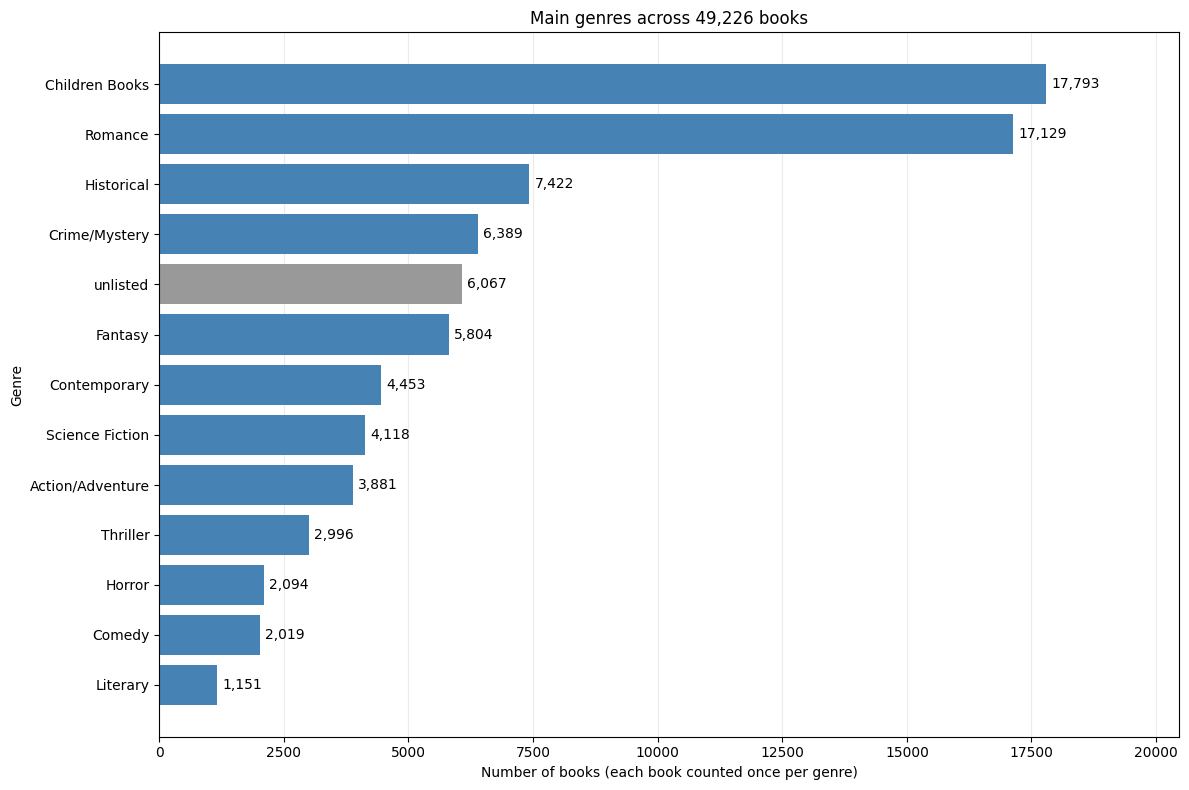

Saved:
data\processed\books_selected_genres.json
data\processed\books_selected_genres.parquet
data\processed\selected_genre_counts.txt
data\processed\selected_genre_popularity.png


In [116]:

import re
import unicodedata
from pathlib import Path

import ftfy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator

PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
UNLISTED = "unlisted"

GENRE_PATTERNS = {
    "Crime/Mystery": r"\b(?:crime|mystery)\b",
    "Romance": r"\b(?:romance|romans)\b",
    "Fantasy": r"\bfantasy\b",
    "Contemporary": r"\bcontemporary\b",
    "Science Fiction": r"\bscience fiction\b",
    "Action/Adventure": r"\b(?:action|adventure)\b",
    "Horror": r"\bhorror\b",
    "Literary": r"\bliterary\b",
    "Comedy": r"\b(?:comedy|humorous)\b",
    "Children Books": r"\b(?:children|childrens|juvenile)\b",
    "Historical": r"\bhistorical\b",
    "Thriller": r"\b(?:thriller|thrillers)\b",
}

GENRE_RULES = {
    genre: re.compile(pattern)
    for genre, pattern in GENRE_PATTERNS.items()
}

CATALOG_PREFIX = re.compile(
    r"^(?:collectionid|collection|nyt|series|serie|reading level)\b"
)


def normalize_genre(label: str) -> str:
    text = ftfy.fix_text(label, normalization="NFKC").casefold()
    text = "".join(
        ch for ch in text
        if unicodedata.category(ch) != "Cf"
    )
    text = re.sub(r"['\u2018\u2019]", "", text)
    text = re.sub(r"[^\w\s]|\_", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def assign_main_genres(tags: list[str]) -> list[str]:
    """Clean tags first; keep only selected genres on a match, otherwise append unlisted."""

    if not isinstance(tags, list) or any(
        not isinstance(tag, str) for tag in tags
    ):
        raise TypeError(
            "Each book's genres must be a list of strings."
        )

    cleaned_tags = list(
        dict.fromkeys(
            label
            for tag in tags
            if (label := normalize_genre(tag))
        )
    )

    labels = [
        label for label in cleaned_tags
        if not CATALOG_PREFIX.match(label)
    ]

    matches = [
        genre
        for genre, pattern in GENRE_RULES.items()
        if any(pattern.search(label) for label in labels)
    ]

    return matches if matches else list(
        dict.fromkeys([*cleaned_tags, UNLISTED])
    )


# Korzystamy bezpośrednio z oczyszczonego DataFrame
books = books_updated.copy()

if books.empty:
    raise ValueError("The source book dataset is empty.")

if books["work_key"].isna().any() or books["work_key"].duplicated().any():
    raise ValueError("Expected one non-null, unique work_key per book.")


# Konwersja numpy.ndarray na zwykłe listy
books["genres"] = books["genres"].apply(
    lambda x: x.tolist() if isinstance(x, np.ndarray) else x
)

# Sprawdzenie typów danych
print("Typy genres po konwersji:")
print(books["genres"].apply(type).value_counts())


# Zapisujemy oczyszczony stan bazowy na dysk
books.to_json(
    PROCESSED_DIR / "books_cleaned.json",
    orient="records",
    force_ascii=False,
    indent=2
)

books.to_parquet(
    PROCESSED_DIR / "books_cleaned.parquet",
    engine="pyarrow",
    index=False
)


# Klasyfikacja gatunków
classified = books.copy()
classified["genres"] = books["genres"].map(assign_main_genres)


# Liczenie wystąpień poszczególnych gatunków
counts = (
    classified["genres"]
    .map(lambda tags: list(dict.fromkeys(tags)))
    .explode()
    .value_counts()
    .reindex([*GENRE_RULES, UNLISTED], fill_value=0)
)


# Ścieżki plików wynikowych
json_path = PROCESSED_DIR / "books_selected_genres.json"
parquet_path = PROCESSED_DIR / "books_selected_genres.parquet"
report_path = PROCESSED_DIR / "selected_genre_counts.txt"
chart_path = PROCESSED_DIR / "selected_genre_popularity.png"


# Zapis sklasyfikowanego zbioru
classified.to_json(
    json_path,
    orient="records",
    force_ascii=False,
    indent=2
)

classified.to_parquet(
    parquet_path,
    engine="pyarrow",
    index=False
)


# Przygotowanie raportu
unlisted_count = int(counts[UNLISTED])

lines = [
    f"Total books: {len(classified):,}",
    f"Books with at least one selected genre: {len(classified) - unlisted_count:,}",
    f"Books with no matching selected genre ({UNLISTED}): {unlisted_count:,}",
    "",
    "Books per genre:",
    *[f"{genre}: {count:,}" for genre, count in counts.items()],
    "",
    "Before matching, tags are lowercased, Unicode-repaired, stripped of punctuation and invisible characters, and whitespace-normalized.",
    "Empty tags and duplicates created by cleaning are removed.",
    "Matching uses normalized category words within existing tags and the explicit mappings below.",
    "Crime or mystery -> Crime/Mystery; action or adventure -> Action/Adventure.",
    "Children, children's, or juvenile -> Children Books; comedy or humorous -> Comedy.",
    "Catalog metadata tags are ignored when matching selected genres.",
    "Matched books keep only selected genres; all other tags are removed.",
    "Unmatched books retain their cleaned tags and gain unlisted exactly once.",
    "The source books.json and books.parquet files are not modified.",
    "A book can have multiple genres, but counts only once per genre.",
    "Genre counts therefore need not sum to the total number of books.",
]

report = "\n".join(lines) + "\n"
report_path.write_text(report, encoding="utf-8")

print(report)


# Generowanie wykresu
plot_counts = counts.sort_values(
    ascending=False,
    kind="stable"
)

fig, ax = plt.subplots(figsize=(12, 8))

colors = [
    "#999999" if genre == UNLISTED else "steelblue"
    for genre in plot_counts.index
]

bars = ax.barh(
    plot_counts.index,
    plot_counts.values,
    color=colors
)

ax.invert_yaxis()

ax.bar_label(
    bars,
    labels=[f"{count:,}" for count in plot_counts],
    padding=4
)

ax.set(
    title=f"Main genres across {len(classified):,} books",
    xlabel="Number of books (each book counted once per genre)",
    ylabel="Genre",
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.15)

fig.tight_layout()

fig.savefig(
    chart_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


print(
    f"Saved:\n"
    f"{json_path}\n"
    f"{parquet_path}\n"
    f"{report_path}\n"
    f"{chart_path}"
)


Initial book count: 49,226
Removed books with no matching target genre: 6,031
Remaining books with specific genres: 43,195



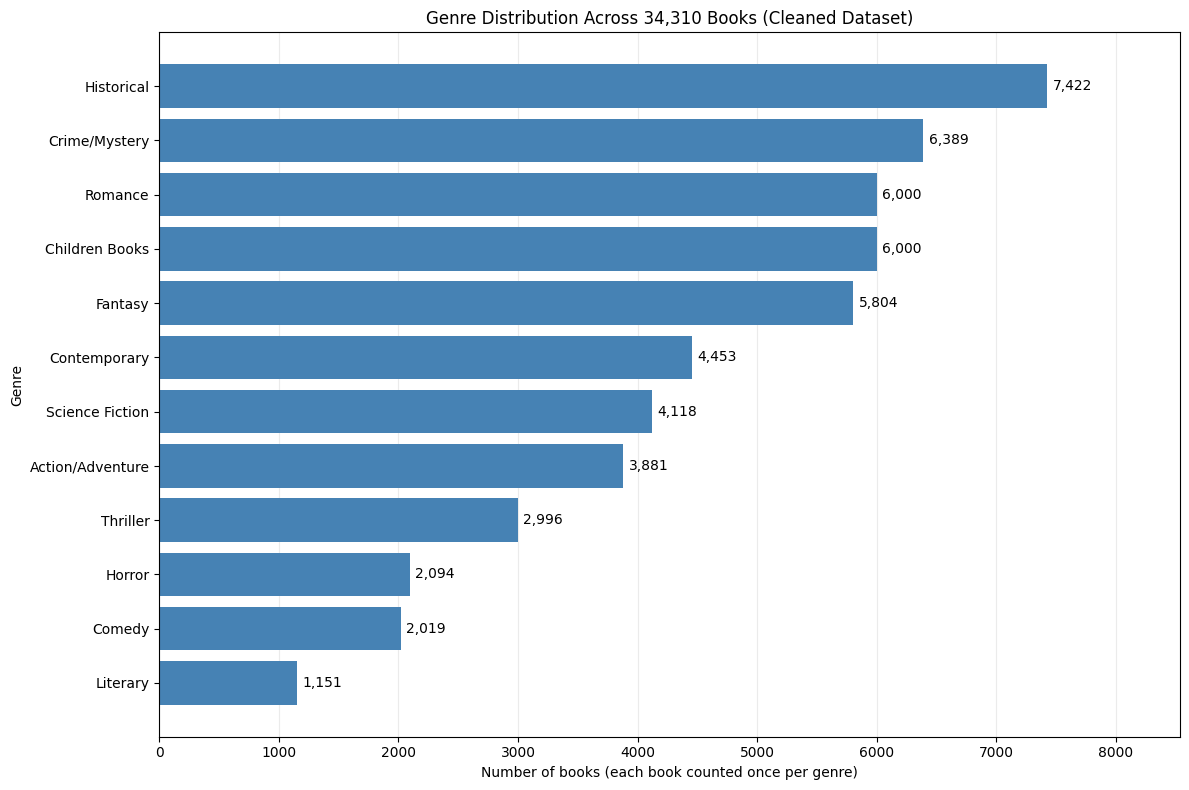

Total books in cleaned dataset: 34,310

Final Genre Counts:
Crime/Mystery: 6,389
Romance: 6,000
Fantasy: 5,804
Contemporary: 4,453
Science Fiction: 4,118
Action/Adventure: 3,881
Horror: 2,094
Literary: 1,151
Comedy: 2,019
Children Books: 6,000
Historical: 7,422
Thriller: 2,996

Final dataset record count: 34,310
Saved visualization to: data\processed\clean_genre_distribution.png


In [123]:

import numpy as np
import random
import re
import unicodedata
from pathlib import Path

import ftfy
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

PROCESSED_DIR = Path("data/processed")

GENRE_PATTERNS = {
    "Crime/Mystery": r"\b(?:crime|mystery)\b",
    "Romance": r"\bromance|romans\b",
    "Fantasy": r"\bfantasy\b",
    "Contemporary": r"\bcontemporary\b",
    "Science Fiction": r"\bscience fiction\b",
    "Action/Adventure": r"\b(?:action|adventure)\b",
    "Horror": r"\bhorror\b",
    "Literary": r"\bliterary\b",
    "Comedy": r"\b(?:comedy|humorous)\b",
    "Children Books": r"\b(?:children|childrens|juvenile)\b",
    "Historical": r"\bhistorical\b",
    "Thriller": r"\b(?:thriller|thrillers)\b",
}

GENRE_RULES = {genre: re.compile(pattern) for genre, pattern in GENRE_PATTERNS.items()}
CATALOG_PREFIX = re.compile(r"^(?:collectionid|collection|nyt|series|serie|reading level)\b")

DOMINANT_GENRES = {"Children Books", "Romance"}
TARGET_LIMIT = 6000


def normalize_genre(label: str) -> str:
    text = ftfy.fix_text(label, normalization="NFKC").casefold()
    text = "".join(ch for ch in text if unicodedata.category(ch) != "Cf")
    text = re.sub(r"['\u2018\u2019]", "", text)
    text = re.sub(r"[^\w\s]|_", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def get_matched_genres(tags: list[str]) -> list[str]:
    if not isinstance(tags, list) or any(not isinstance(tag, str) for tag in tags):
        raise TypeError("Each book's genres must be a list of strings.")
    
    cleaned_tags = list(dict.fromkeys(label for tag in tags if (label := normalize_genre(tag))))
    labels = [label for label in cleaned_tags if not CATALOG_PREFIX.match(label)]
    
    matches = [
        genre
        for genre, pattern in GENRE_RULES.items()
        if any(pattern.search(label) for label in labels)
    ]
    return list(dict.fromkeys(matches))


raw_json_path = PROCESSED_DIR / "books_cleaned.parquet"
books = pd.read_parquet(raw_json_path)

books["genres"] = books["genres"].apply(
    lambda x: x.tolist() if isinstance(x, np.ndarray) else x
)

books["genres"] = books["genres"].map(get_matched_genres)

has_genre_mask = books["genres"].map(lambda tags: len(tags) > 0)
books_clean = books[has_genre_mask].reset_index(drop=True)

print(f"Initial book count: {len(books):,}")
print(f"Removed books with no matching target genre: {(~has_genre_mask).sum():,}")
print(f"Remaining books with specific genres: {len(books_clean):,}\n")

random.seed(42)
shuffled_indices = list(books_clean.index)
random.shuffle(shuffled_indices)

dominant_counts = {g: 0 for g in DOMINANT_GENRES}
new_genres_dict = {}

for idx in shuffled_indices:
    matched = books_clean.loc[idx, "genres"]
    updated_genres = []
    
    for g in matched:
        if g in DOMINANT_GENRES:
            if dominant_counts[g] < TARGET_LIMIT:
                updated_genres.append(g)
                dominant_counts[g] += 1
        else:
            updated_genres.append(g)
            
    new_genres_dict[idx] = updated_genres

classified = books_clean.copy()
classified["genres"] = classified.index.map(new_genres_dict)

final_mask = classified["genres"].map(lambda tags: len(tags) > 0)
classified = classified[final_mask].reset_index(drop=True)

clean_parquet_path = PROCESSED_DIR / "books_clean_balanced.parquet"
clean_json_path = PROCESSED_DIR / "books_clean_balanced.json"

classified.to_json(clean_json_path, orient="records", force_ascii=False, indent=2)
classified.to_parquet(clean_parquet_path, engine="pyarrow", index=False)

counts = (
    classified["genres"]
    .map(lambda tags: list(dict.fromkeys(tags)))
    .explode()
    .value_counts()
    .reindex(list(GENRE_RULES.keys()), fill_value=0)
)

plot_counts = counts.sort_values(ascending=False, kind="stable")

chart_path = PROCESSED_DIR / "clean_genre_distribution.png"
report_path = PROCESSED_DIR / "clean_genre_counts.txt"

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(plot_counts.index, plot_counts.values, color="steelblue")

ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{count:,}" for count in plot_counts], padding=4)
ax.set(
    title=f"Genre Distribution Across {len(classified):,} Books (Cleaned Dataset)",
    xlabel="Number of books (each book counted once per genre)",
    ylabel="Genre",
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.15)
fig.tight_layout()

fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

lines = [
    f"Total books in cleaned dataset: {len(classified):,}",
    "",
    "Final Genre Counts:",
    *[f"{genre}: {count:,}" for genre, count in counts.items()],
]
report = "\n".join(lines) + "\n"
report_path.write_text(report, encoding="utf-8")

print(report)
print(f"Final dataset record count: {len(classified):,}")
print(f"Saved visualization to: {chart_path}")


In [124]:
print("\n20 example book descriptions:\n")

for i, row in classified.head(20).iterrows():
    print(f"TITLE: {row['title']}")
    print(f"GENRES: {', '.join(row['genres'])}")
    print(f"DESCRIPTION:\n{row['desc_cleaned']}")
    print("-" * 100)


20 example book descriptions:

TITLE: It Ends With Us
GENRES: Contemporary
DESCRIPTION:
Lily hasn’t always had it easy, but that’s never stopped her from working hard for the life she wants. She’s come a long way from the small town where she grew up—she graduated from college, moved to Boston, and started her own business. And when she feels a spark with a gorgeous neurosurgeon named Ryle Kincaid, everything in Lily’s life seems too good to be true.

Ryle is assertive, stubborn, maybe even a little arrogant. He’s also sensitive, brilliant, and has a total soft spot for Lily. And the way he looks in scrubs certainly doesn’t hurt. Lily can’t get him out of her head. But Ryle’s complete aversion to relationships is disturbing. Even as Lily finds herself becoming the exception to his “no dating” rule, she can’t help but wonder what made him that way in the first place.

As questions about her new relationship overwhelm her, so do thoughts of Atlas Corrigan—her first love and a link to th